In [22]:
import pandas as pd
import numpy as np
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

In [2]:
# --- 1. Define Bulk Densities ---
L_nm = 4.66486314
vol_nm3 = L_nm**3

# Dictionary of bulk densities (particles / nm^3)
bulk_rho = {
    "N(TMA)": 6 / vol_nm3,
    "B(BF4)": 6 / vol_nm3,
    "O(THF)": 370 / vol_nm3,
    "O(EtOH)": 500 / vol_nm3,
    "S(MTC)": 16 / vol_nm3, 
    "S(Thioph)": 16 / vol_nm3 
}

R_gas = 8.314 # J/mol K
T_sys = 298.15 # K


# Load Data
rdf_data = pd.read_csv('bulk_16MTC6ion_RDF.csv')


# --- 2. Function for Full Profile (PMF & CN vs r) ---
def calculate_r_profile(r, g, neighbor_species, bulk_densities, T=298.15):
    """
    Calculates PMF and running Coordination Number (CN) over the entire r range.
    
    Parameters:
    - r: Array of radial distances.
    - g: Array of RDF values g(r).
    - neighbor_species: Name of the neighbor species (to lookup density).
    - bulk_densities: Dictionary of densities.
    
    Returns:
    - pmf_profile: Array of PMF values (kJ/mol).
    - cn_profile: Array of cumulative CN values.
    """
    # 1. PMF Profile
    # Handle zeros to avoid log(0)
    with np.errstate(divide='ignore'):
        pmf_profile = -R_gas * T * np.log(g) / 1000.0 # kJ/mol
    # Replace inf with nan or a large number if desired
    pmf_profile[g == 0] = np.inf 

    # 2. Running CN Profile
    # Get density of the NEIGHBOR
    rho_nm3 = bulk_densities.get(neighbor_species)
    if rho_nm3 is None:
        print(f"Warning: Density not found for {neighbor_species}")
        return pmf_profile, np.full_like(r, np.nan)
        
    rho_A3 = rho_nm3 * 0.001 # Convert nm^-3 to A^-3

    # Integrate: n(r) = integral_0^r (4*pi*s^2 * rho * g(s)) ds
    integrand = 4 * np.pi * (r**2) * rho_A3 * g
    
    # Cumulative trapezoidal integration
    # cumtrapz returns array of length N-1, so we prepend 0
    from scipy.integrate import cumulative_trapezoid
    cn_profile = cumulative_trapezoid(integrand, x=r, initial=0)
    
    return pmf_profile, cn_profile

# --- 3. Function for Solvation Shell Extraction (Peak & Cutoff) ---
def extract_solvation_shell_params(df, bulk_densities, T=298.15, manual_cutoffs=None, peak_search_ranges=None):
    """
    Analyzes RDFs to find Peak, Cutoff, and specific Solvation Shell CN.
    Processes both A-B and B-A perspectives for each pair.
    
    Parameters:
    - peak_search_ranges: Dict of {'PairName': (r_min, r_max)} to restrict peak search.
      Example: {"N(TMA)-B(BF4)": (4.0, 6.0)}
    """
    if manual_cutoffs is None:
        manual_cutoffs = {}
    if peak_search_ranges is None:
        peak_search_ranges = {}
        
    r_vals = df['r'].values
    results = []
    
    # Iterate over raw pairs in the CSV
    for pair_col in df.columns:
        if pair_col == 'r':
            continue
            
        g_vals = df[pair_col].values
        
        # Parse the pair name "A-B"
        parts = pair_col.split('-')
        species_A = parts[0]
        species_B = parts[1]
        
        # Determine perspectives to calculate
        perspectives = [(species_A, species_B)]
        if species_A != species_B:
            perspectives.append((species_B, species_A))
            
        for center, neighbor in perspectives:
            
            # 1. Get Density of the NEIGHBOR
            rho_nm3 = bulk_densities.get(neighbor)
            rho_A3 = rho_nm3 * 0.001 if rho_nm3 else np.nan
            
            # 2. Find Peak with Optional Range Restriction
            # Default: Search over full range
            
            # Define indices to search
            valid_indices = np.arange(len(g_vals))
            
            # Apply Range Restriction if defined for this pair
            if pair_col in peak_search_ranges:
                r_min, r_max = peak_search_ranges[pair_col]
                mask = (r_vals >= r_min) & (r_vals <= r_max)
                valid_indices = np.where(mask)[0]
            
            # Subset g(r) for search
            if len(valid_indices) > 0:
                search_g = g_vals[valid_indices]
                # Find peaks in the constrained region
                peaks, _ = find_peaks(search_g, prominence=0.1)
            else:
                peaks = []
            
            if len(peaks) > 0:
                # Map local peak index back to global index
                peak_true = "Yes"
                local_peak_idx = peaks[0]
                global_peak_idx = valid_indices[local_peak_idx]
                
                r_peak = r_vals[global_peak_idx]
                g_peak = g_vals[global_peak_idx]
                
                # PMF at peak
                R_gas = 8.314
                pmf_val = -R_gas * T * np.log(g_peak) / 1000.0 if g_peak > 0 else np.inf
                
                # 3. Determine Cutoff
                # Check manual override
                cutoff_r = np.nan
                cutoff_method = "Auto"
                
                if pair_col in manual_cutoffs:
                    cutoff_r = manual_cutoffs[pair_col]
                    cutoff_idx = (np.abs(r_vals - cutoff_r)).argmin()
                    cutoff_method = "Manual"
                else:
                    # Auto detection (First minimum after peak)
                    cutoff_idx = -1
                    found_min = False
                    # Search from the peak onwards
                    for i in range(global_peak_idx, len(g_vals) - 1):
                        if g_vals[i+1] > g_vals[i]: 
                            cutoff_idx = i
                            found_min = True
                            break
                    
                    if found_min:
                        cutoff_r = r_vals[cutoff_idx]
                    else:
                        cutoff_method = "Failed"
                
                # 4. Integrate CN
                if not np.isnan(cutoff_r) and not np.isnan(rho_A3):
                    r_slice = r_vals[:cutoff_idx+1]
                    g_slice = g_vals[:cutoff_idx+1]
                    integrand = 4 * np.pi * (r_slice**2) * rho_A3 * g_slice
                    cn_val = np.trapz(integrand, x=r_slice)
                else:
                    cn_val = np.nan
                    
            else:
                # No peak found
                peak_true = "No Peak"
                r_peak, g_peak, pmf_val, cutoff_r, cn_val = np.nan, np.nan, np.nan, np.nan, 0.0
                cutoff_method = "No Peak"

                if pair_col in manual_cutoffs:
                    cutoff_r = manual_cutoffs[pair_col]
                    cutoff_idx = (np.abs(r_vals - cutoff_r)).argmin()
                    cutoff_method = "Manual"
                    
                    if not np.isnan(cutoff_r) and not np.isnan(rho_A3):
                        r_slice = r_vals[:cutoff_idx+1]
                        g_slice = g_vals[:cutoff_idx+1]
                        integrand = 4 * np.pi * (r_slice**2) * rho_A3 * g_slice
                        cn_val = np.trapz(integrand, x=r_slice)
                    else:
                        cn_val = np.nan
            
            results.append({
                "Original_Pair": pair_col,
                "Center_Species": center,
                "Neighbor_Species": neighbor,
                "X_neighbor": bulk_densities.get(neighbor, 0) / sum(bulk_densities.values()),
                "Peak_exist": peak_true,
                "Peak_r (Angstrom)": r_peak,
                "Peak_gr": g_peak,
                "PMF_well_depth (kJ/mol)": pmf_val,
                "Cutoff_Used (Å)": cutoff_r,
                "Method": cutoff_method,
                "CN": cn_val
            })

    res_df = pd.DataFrame(results)
    res_df.sort_values(by=['Center_Species', 'Neighbor_Species'], inplace=True)
    return res_df

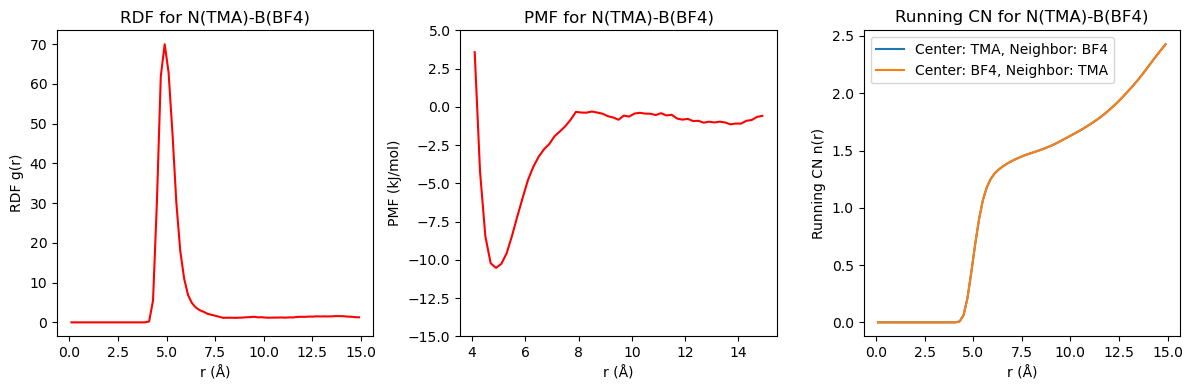

In [3]:

# B. Get Full Profiles for a specific pair (Example)
# This allows you to plot or inspect the full n(r) curve
pair_name = "N(TMA)-B(BF4)"
r_vals = rdf_data['r']
g_vals = rdf_data[pair_name]

# Perspective 1: TMA center, BF4 neighbor
pmf_TMA, cn_TMA = calculate_r_profile(r_vals, g_vals, "B(BF4)", bulk_rho)

# Perspective 2: BF4 center, TMA neighbor
pmf_BF4, cn_BF4 = calculate_r_profile(r_vals, g_vals, "N(TMA)", bulk_rho)

# Plotting check
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 3)
plt.plot(r_vals, cn_TMA, label="Center: TMA, Neighbor: BF4")
plt.plot(r_vals, cn_BF4, label="Center: BF4, Neighbor: TMA")
plt.xlabel("r (Å)")
plt.ylabel("Running CN n(r)")
plt.legend()
plt.title(f"Running CN for {pair_name}")

plt.subplot(1, 3, 2)
plt.plot(r_vals, pmf_TMA, color='red')
plt.xlabel("r (Å)")
plt.ylabel("PMF (kJ/mol)")
plt.ylim(-15, 5)
plt.title(f"PMF for {pair_name}")

plt.subplot(1, 3, 1)
plt.plot(r_vals, g_vals, color='red')
plt.xlabel("r (Å)")
plt.ylabel("RDF g(r)")
# plt.ylim(-15, 5)
plt.title(f"RDF for {pair_name}")
plt.tight_layout()
plt.show()

In [4]:
# --- 1. Setup Colors and Species ---
species_list = ['N(TMA)', 'B(BF4)', 'O(EtOH)', 'O(THF)', 'S(MTC)']
colors_list = ['navy', 'hotpink', 'skyblue', 'tab:green', 'tab:orange'] # Used hotpink for better visibility than 'pink'
SPECIES_COLOR = dict(zip(species_list, colors_list))

# --- 2. Helper to find Data Column ---
def get_pair_data(df, sp1, sp2):
    # Try A-B
    if f"{sp1}-{sp2}" in df.columns:
        return df[f"{sp1}-{sp2}"], False # False = not flipped
    # Try B-A
    elif f"{sp2}-{sp1}" in df.columns:
        return df[f"{sp2}-{sp1}"], True # True = flipped (order reversed in name)
    return None, False


In [5]:
# --- 4. Execution Example ---

# Optional Overrides
my_cutoffs = {
    "N(TMA)-B(BF4)": 5.5, 
    "B(BF4)-B(BF4)": 5.5, 
    "N(TMA)-N(TMA)": 6.5, 
    "B(BF4)-O(THF)": 5.0,
    "O(EtOH)-S(MTC)": 7.0,
    "N(TMA)-S(MTC)": 7.0,
    "B(BF4)-S(MTC)": 7.0,
    "O(THF)-O(THF)": 5.5,
    "O(THF)-O(EtOH)": 4.0,
    "O(EtOH)-O(EtOH)": 4.0,
    "O(THF)-S(MTC)": 7.0,
    "S(MTC)-S(MTC)": 7.0,
}

peak_ranges = {
    "B(BF4)-B(BF4)": (2.0, 6.0),
    "N(TMA)-N(TMA)": (2.0, 6.0),
}

# A. Get Summary Table
summary_table = extract_solvation_shell_params(rdf_data, bulk_rho, manual_cutoffs=my_cutoffs, peak_search_ranges=peak_ranges)

# Display Summary
pd.set_option('display.max_columns', None)
print("Solvation Shell Analysis (Sorted by Center):")
display(summary_table)

# Optional: Save to CSV
summary_table.to_csv('rdf_shell_analysis.csv', index=False)


Solvation Shell Analysis (Sorted by Center):


C:\Users\Chaoxuan Gu\AppData\Local\Temp\ipykernel_40736\30661802.py:168: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  cn_val = np.trapz(integrand, x=r_slice)
C:\Users\Chaoxuan Gu\AppData\Local\Temp\ipykernel_40736\30661802.py:187: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  cn_val = np.trapz(integrand, x=r_slice)


,Original_Pair,Center_Species,Neighbor_Species,X_neighbor,Peak_exist,Peak_r (Angstrom),Peak_gr,PMF_well_depth (kJ/mol),Cutoff_Used (Å),Method,CN
24,B(BF4)-B(BF4),B(BF4),B(BF4),0.006565,No Peak,NaN,NaN,NaN,5.5,Manual,0.000946
11,N(TMA)-B(BF4),B(BF4),N(TMA),0.006565,Yes,4.9,69.950142,-10.529485,5.5,Manual,1.068685
12,B(BF4)-O(EtOH),B(BF4),O(EtOH),0.547046,Yes,3.7,9.980888,-5.702950,4.5,Auto,4.636326
14,B(BF4)-O(THF),B(BF4),O(THF),0.404814,No Peak,NaN,NaN,NaN,5.0,Manual,0.143052
16,B(BF4)-S(MTC),B(BF4),S(MTC),0.017505,Yes,9.1,0.944745,0.140898,7.0,Manual,0.058383
10,N(TMA)-B(BF4),N(TMA),B(BF4),0.006565,Yes,4.9,69.950142,-10.529485,5.5,Manual,1.068685
23,N(TMA)-N(TMA),N(TMA),N(TMA),0.006565,No Peak,NaN,NaN,NaN,6.5,Manual,0.054386
4,N(TMA)-O(EtOH),N(TMA),O(EtOH),0.547046,Yes,4.3,4.261527,-3.593364,7.1,Auto,10.764027
6,N(TMA)-O(THF),N(TMA),O(THF),0.404814,Yes,4.1,1.779217,-1.428229,5.7,Auto,1.956230
8,N(TMA)-S(MTC),N(TMA),S(MTC),0.017505,Yes,5.1,0.537234,1.540145,7.0,Manual,0.069265


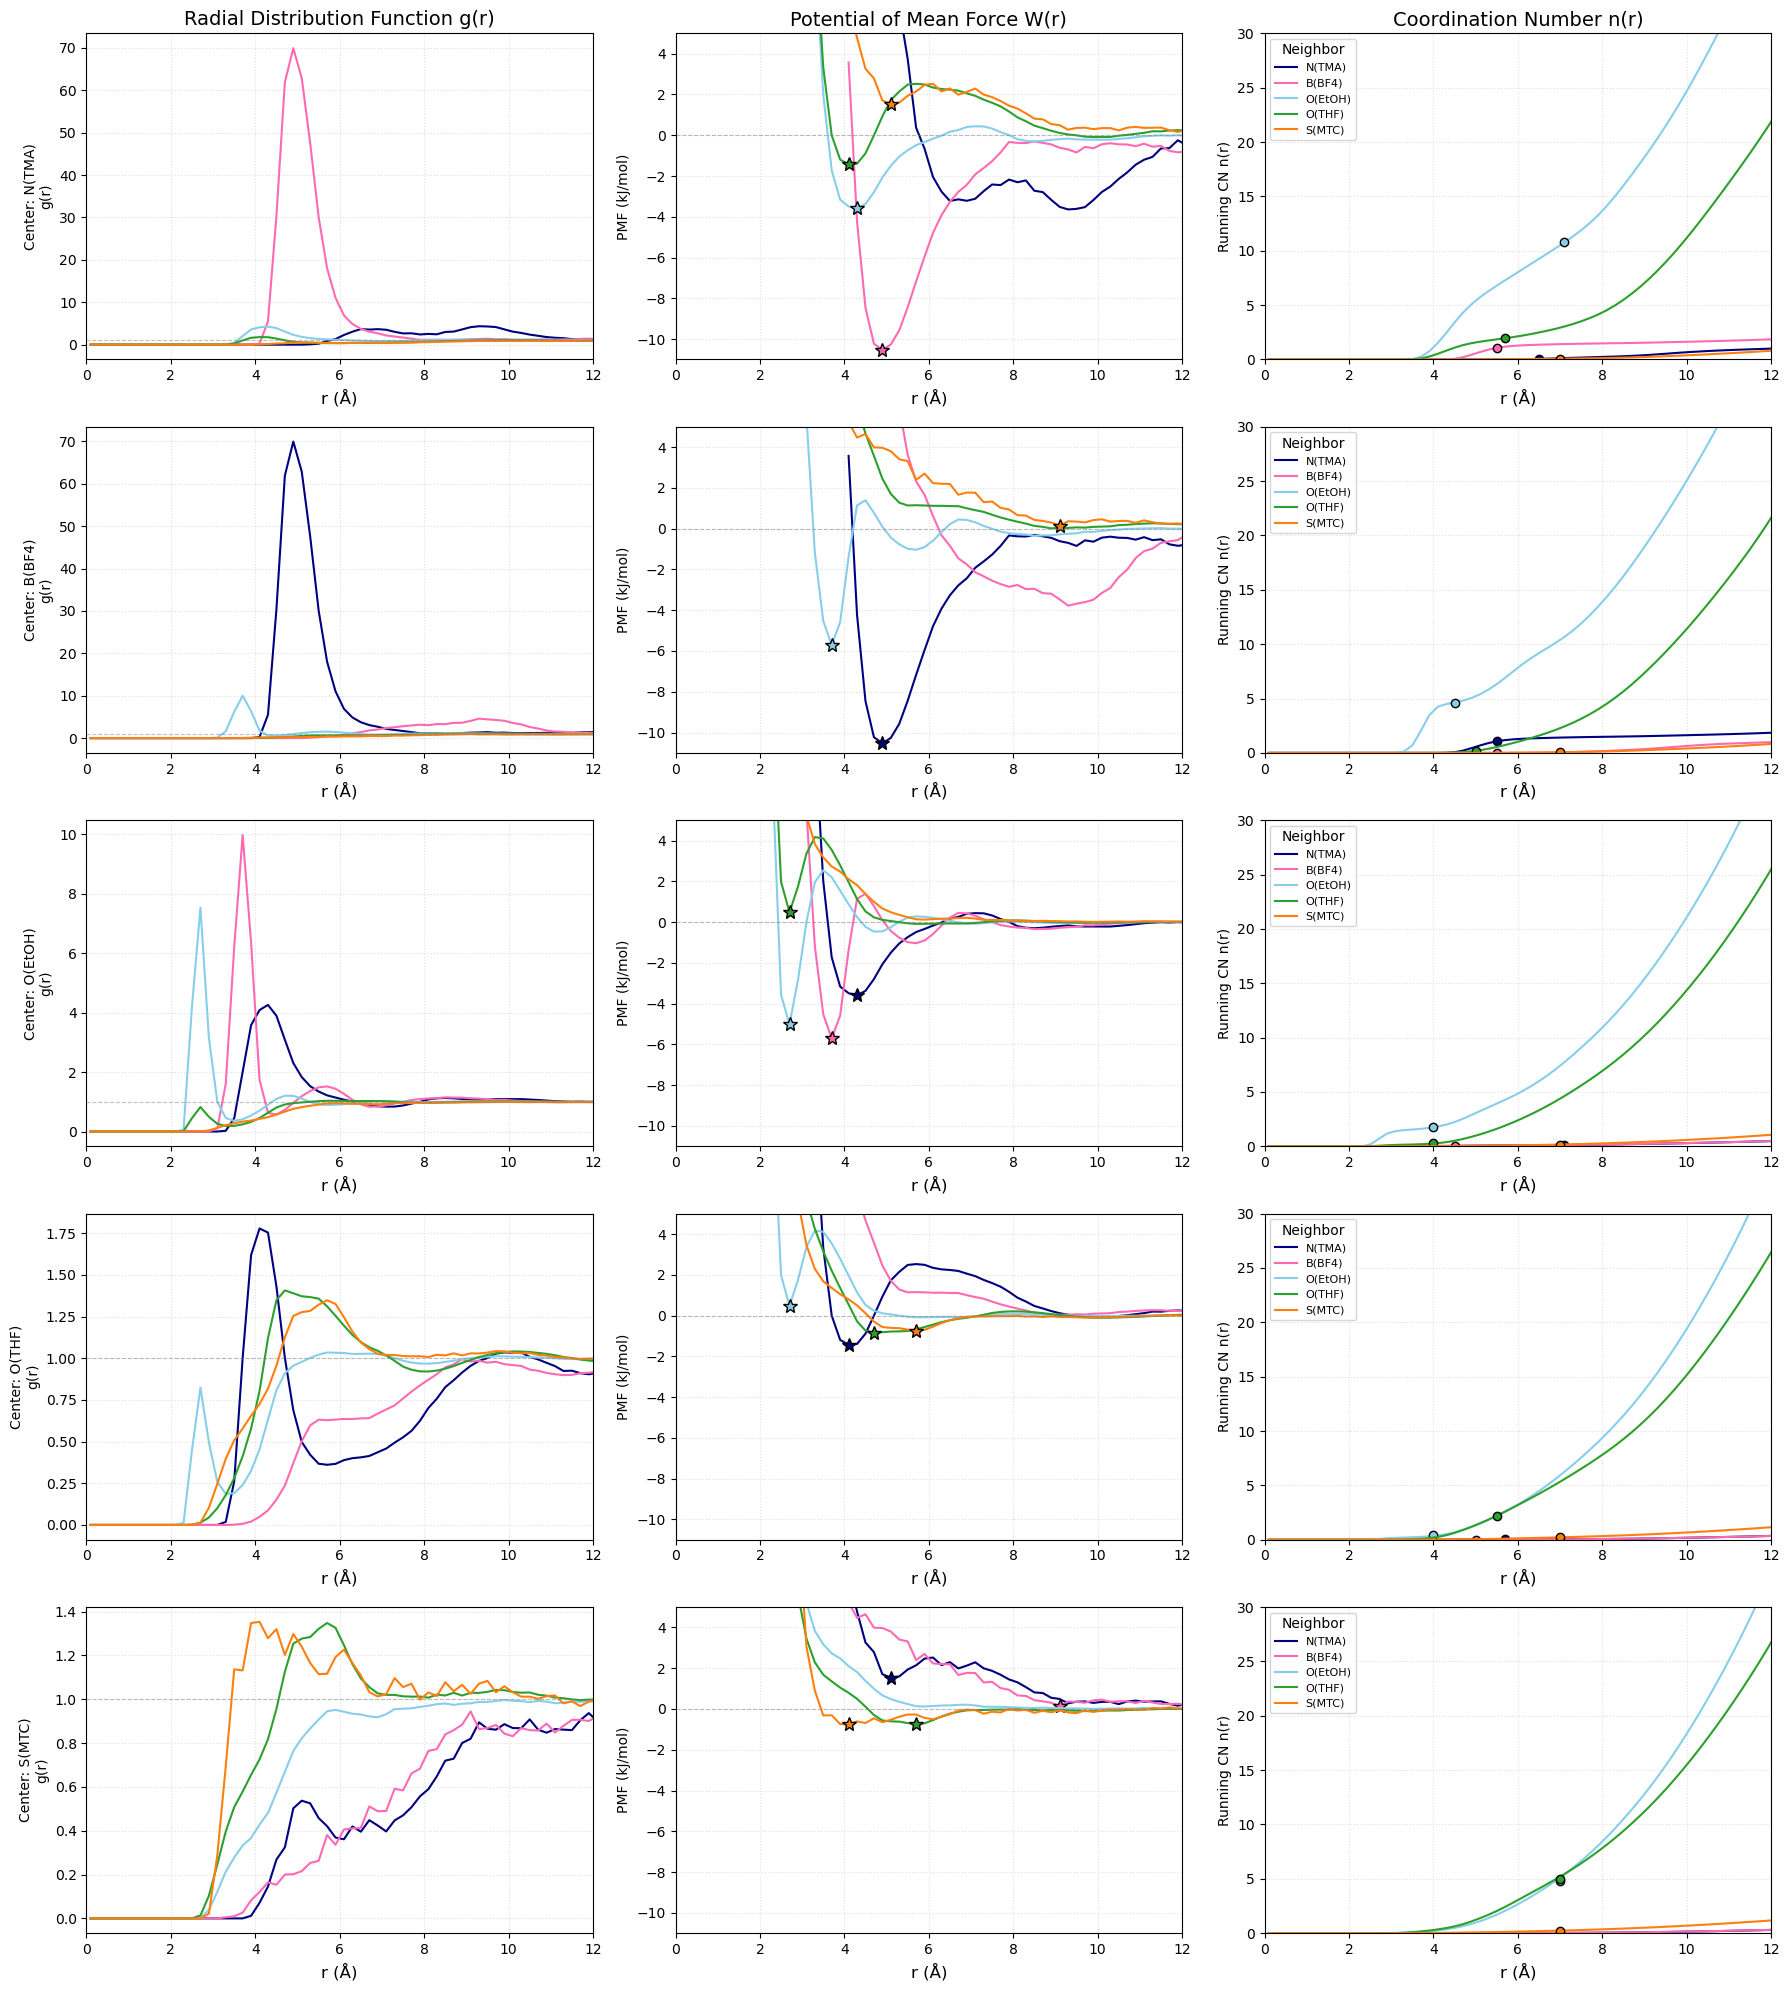

In [6]:

# --- 3. Generate the Figure ---
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(18, 20), sharex=False)
r_vals = rdf_data['r']

# Iterate over Centers (Rows)
for i, center in enumerate(species_list):
    
    # Iterate over Neighbors (Curves)
    for neighbor in species_list:
        color = SPECIES_COLOR[neighbor]
        
        # A. Get Raw RDF Data
        g_vals_raw, is_flipped = get_pair_data(rdf_data, center, neighbor)
        
        if g_vals_raw is None:
            continue
            
        # B. Calculate Profiles
        # Note: calculate_r_profile handles the "Neighbor Density" logic automatically
        pmf_profile, cn_profile = calculate_r_profile(r_vals.values, g_vals_raw.values, neighbor, bulk_rho)
        
        # C. Get Scalar Params for Annotation (Peak & Cutoff)
        # We query the summary_table generated in the previous step
        row_stats = summary_table[
            (summary_table['Center_Species'] == center) & 
            (summary_table['Neighbor_Species'] == neighbor)
        ]
        
        # Plot 1: RDF
        ax_rdf = axes[i, 0]
        ax_rdf.plot(r_vals, g_vals_raw, color=color, label=neighbor, linewidth=1.5)
        
        # Plot 2: PMF
        ax_pmf = axes[i, 1]
        ax_pmf.plot(r_vals, pmf_profile, color=color, label=neighbor, linewidth=1.5)
        
        # Plot 3: CN
        ax_cn = axes[i, 2]
        ax_cn.plot(r_vals, cn_profile, color=color, label=neighbor, linewidth=1.5)
        
        # --- Annotations ---
        if not row_stats.empty:
            # 1. PMF Peak (Minimum Energy)
            r_peak = row_stats.iloc[0]['Peak_r (Angstrom)']
            w_peak = row_stats.iloc[0]['PMF_well_depth (kJ/mol)']
            
            if not np.isnan(r_peak) and not np.isnan(w_peak):
                ax_pmf.plot(r_peak, w_peak, marker='*', markersize=10, 
                            color=color, markeredgecolor='black', linestyle='None')
            
            # 2. CN Cutoff
            r_cut = row_stats.iloc[0]['Cutoff_Used (Å)']
            cn_val = row_stats.iloc[0]['CN']
            
            if not np.isnan(r_cut) and not np.isnan(cn_val):
                # We need the y-value of the curve at r_cut to plot the marker ON the line
                # (cn_val is the integration result, which should match the curve at r_cut)
                ax_cn.plot(r_cut, cn_val, marker='o', markersize=6, 
                           color=color, markeredgecolor='black', linestyle='None')

    # Row Formatting
    # RDF
    axes[i, 0].set_ylabel(f"Center: {center}\ng(r)")
    axes[i, 0].axhline(1, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
    
    # PMF
    axes[i, 1].set_ylabel("PMF (kJ/mol)")
    axes[i, 1].axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
    axes[i, 1].set_ylim(-11, 5) # Zoom in on the wells
    
    # CN
    axes[i, 2].set_ylabel("Running CN n(r)")
    axes[i, 2].legend(title="Neighbor", fontsize=8, loc='upper left')
    axes[i, 2].set_ylim(0, 30)

    # X-Axis Labels (Bottom Row only)
    axes[i, 0].set_xlabel("r (Å)", fontsize=12)
    axes[i, 1].set_xlabel("r (Å)", fontsize=12)
    axes[i, 2].set_xlabel("r (Å)", fontsize=12)

    axes[i, 0].set_xlim(0, 12)
    axes[i, 1].set_xlim(0, 12)
    axes[i, 2].set_xlim(0, 12)

    axes[i, 0].grid(True, linestyle=':', alpha=0.4)
    axes[i, 1].grid(True, linestyle=':', alpha=0.4)
    axes[i, 2].grid(True, linestyle=':', alpha=0.4)

# Titles (Top Row only)
axes[0, 0].set_title("Radial Distribution Function g(r)", fontsize=14)
axes[0, 1].set_title("Potential of Mean Force W(r)", fontsize=14)
axes[0, 2].set_title("Coordination Number n(r)", fontsize=14)

plt.tight_layout()
plt.savefig('rdf_pmf_cn_summary.png', dpi=300)
plt.show()

In [7]:

# --- 1. Thermodynamic Constants ---
R = 8.314        # J/(mol K)
T = 298.15       # Temperature (K)
RT = R * T

# --- 2. System Definition ---
# Species Order: 0:TMA, 1:BF4, 2:EtOH, 3:THF, 4:MTC
species = ['TMA+', 'BF4-', 'EtOH', 'THF', 'MTC']
M = len(species)

# Composition (Global)
conc_molar = np.array([0.099, 0.099, 8.230, 6.090, 0.263]) # mol/L
X = np.array([0.0067, 0.0067, 0.5568, 0.4120, 0.0178])     # Mole Fractions
charges = np.array([1, -1, 0, 0, 0])

# Structural Parameters (from Table 1)
# Coordination Numbers (Z_i)
Z = np.array([13.91, 6.18, 1.88, 8.62, 7.13])

# --- 3. Interaction Parameters (Structure-Consistent Fit) ---
# Derived using the Hybrid Composition-Fitting method (Algorithm C)

# Effective Energy Matrix (Delta Epsilon) in J/mol
# Symmetric: DE_ij = DE_ji
# de_matrix = np.array([
#     [-3224., -11007.,  -9691.,  -1707.,  -4291.],
#     [-11007., -2851.,  -3805.,      0.,  -5364.],
#     [-9691.,  -3805.,  -5006.,   4506.,      0.],
#     [-1707.,      0.,   4506.,   -847.,  -4835.],
#     [-4291.,  -5364.,      0.,  -4835.,   -750.]
# ])

# Affinity Matrix (a_ij)
# a_ij = exp(-DE_ij / RT)
# a_matrix = np.exp(-de_matrix / RT)

# print("System initialized successfully.")
print(f"Species: {species}")

Species: ['TMA+', 'BF4-', 'EtOH', 'THF', 'MTC']


# RDF as a_ij

In [8]:
def get_affinity_from_peak(summary_df, species_order):
    """
    Constructs the symmetric Affinity Matrix (a_ij) directly from RDF Peaks.
    Assumption: a_ij = Peak_g(r). If no peak exists, a_ij = 1.0 (Random Mixing).
    """
    n = len(species_order)
    a_matrix = np.zeros((n, n))
    
    # Helper to lookup peak in the dataframe
    def lookup_peak(s1, s2):
        # Check A-B
        row = summary_df[(summary_df['Center_Species'] == s1) & 
                         (summary_df['Neighbor_Species'] == s2)]
        if not row.empty:
            return row.iloc[0]['Peak_gr']
        return np.nan

    for i in range(n):
        for j in range(n):
            sp_i = species_order[i]
            sp_j = species_order[j]
            
            # 1. Get raw peaks from both perspectives
            val_ij = lookup_peak(sp_i, sp_j) # i looking at j
            val_ji = lookup_peak(sp_j, sp_i) # j looking at i
            
            # 2. Determine consensus value
            # If diagonal (i=i)
            if i == j:
                if not pd.isna(val_ij) and val_ij >= 0.1:
                    a_matrix[i, j] = val_ij
                else:
                    a_matrix[i, j] = 1.0 # Default for self if no peak
            
            # If off-diagonal
            else:
                # Symmetrize: Average available peaks
                peaks = []
                if not pd.isna(val_ij) and val_ij >= 0.1:
                    peaks.append(val_ij)
                else:
                    peaks.append(1.0) # Default for self if no peak
                
                if not pd.isna(val_ji) and val_ji >= 0.1:
                    peaks.append(val_ji)
                else:
                    peaks.append(1.0) # Default for self if no peak
                
                if len(peaks) > 0:
                    a_matrix[i, j] = sum(peaks) / len(peaks)
                else:
                    a_matrix[i, j] = 1.0 # Default random mixing
                    
    return a_matrix

def calculate_local_theta(a_matrix, X_vec):
    """
    Calculates the Local Neighbor Fractions (theta_j|i) given Affinities and Composition.
    Formula: theta_j|i = (X_j * a_ji) / sum_k(X_k * a_ki)
    """
    n = len(X_vec)
    theta_matrix = np.zeros((n, n))
    Lambda_vec = np.zeros(n) # Local partition functions
    
    for i in range(n): # Center species i
        # 1. Calculate Lambda_i (Partition Function)
        # Sum over neighbors k: X_k * a_ki
        # Since a is symmetric, a_ki = a_ik, so we can use row i
        Lambda_i = 0.0
        for k in range(n):
            Lambda_i += X_vec[k] * a_matrix[k, i]
        
        Lambda_vec[i] = Lambda_i
        
        # 2. Calculate Theta_j|i
        for j in range(n): # Neighbor species j
            numerator = X_vec[j] * a_matrix[j, i]
            theta_matrix[i, j] = numerator / Lambda_i
            
    return theta_matrix, Lambda_vec

In [9]:
# --- Setup ---
# Load your summary dataframe (ensure it's loaded from previous steps)
# summary_df = ... 

species_list = ['N(TMA)', 'B(BF4)', 'O(EtOH)', 'O(THF)', 'S(MTC)']
species_labels = ['TMA', 'BF4', 'EtOH', 'THF', 'MTC']

# 1. Define Mole Fractions (X)
# We can extract them from the dataframe or define manually for precision
X_dict = {
    'N(TMA)': 0.0067, 'B(BF4)': 0.0067, 
    'O(EtOH)': 0.5568, 'O(THF)': 0.4120, 'S(MTC)': 0.0178
}
X_vec = np.array([X_dict[sp] for sp in species_list])

# --- Step 1: Get Affinity Matrix (a_ij) ---
a_raw = get_affinity_from_peak(summary_table, species_list)

# --- Inspection ---
print("--- 1. Mole Fractions (X) ---")
print(pd.Series(X_vec, index=species_labels))

print("\n--- 2. Raw Affinity Matrix (a_ij) [From Peaks] ---")
df_a = pd.DataFrame(a_raw, index=species_labels, columns=species_labels)
print(df_a.round(2))

--- 1. Mole Fractions (X) ---
TMA     0.0067
BF4     0.0067
EtOH    0.5568
THF     0.4120
MTC     0.0178
dtype: float64

--- 2. Raw Affinity Matrix (a_ij) [From Peaks] ---
        TMA    BF4  EtOH   THF   MTC
TMA    1.00  69.95  4.26  1.78  0.54
BF4   69.95   1.00  9.98  1.00  0.94
EtOH   4.26   9.98  7.54  0.82  1.00
THF    1.78   1.00  0.82  1.41  1.35
MTC    0.54   0.94  1.00  1.35  1.35


In [10]:
a_raw[0, 1] = a_raw[0, 1]**0.5  # Example adjustment for TMA-BF4 
a_raw[1, 0] = a_raw[0, 1]    # Symmetrize
a_robust = a_raw

print("\n--- 2. Raw Affinity Matrix (a_ij) [From Peaks] ---")
df_a = pd.DataFrame(a_raw, index=species_labels, columns=species_labels)
print(df_a.round(2))


--- 2. Raw Affinity Matrix (a_ij) [From Peaks] ---
       TMA   BF4  EtOH   THF   MTC
TMA   1.00  8.36  4.26  1.78  0.54
BF4   8.36  1.00  9.98  1.00  0.94
EtOH  4.26  9.98  7.54  0.82  1.00
THF   1.78  1.00  0.82  1.41  1.35
MTC   0.54  0.94  1.00  1.35  1.35


In [11]:

# --- Step 2: Get Local Fractions (theta) ---
theta_model, Lambda_vals = calculate_local_theta(a_raw, X_vec)



print("\n--- 3. Local Partition Functions (Lambda_i) ---")
print(pd.Series(Lambda_vals, index=species_labels))

print("\n--- 4. Model Local Fractions (theta_j|i) ---")
# Rows = Center, Cols = Neighbor
df_theta = pd.DataFrame(theta_model, index=species_labels, columns=species_labels)
print(df_theta.round(4))


--- 3. Local Partition Functions (Lambda_i) ---
TMA     3.178154
BF4     6.048911
EtOH    4.648465
THF     1.081231
MTC     1.146326
dtype: float64

--- 4. Model Local Fractions (theta_j|i) ---
         TMA     BF4    EtOH     THF     MTC
TMA   0.0021  0.0176  0.7466  0.2306  0.0030
BF4   0.0093  0.0011  0.9187  0.0681  0.0028
EtOH  0.0061  0.0144  0.9026  0.0730  0.0038
THF   0.0110  0.0062  0.4244  0.5362  0.0222
MTC   0.0031  0.0055  0.4857  0.4846  0.0210


In [12]:
# --- 1. Function to Calculate MD Theta ---
def get_md_theta(summary_df, species_order):
    """
    Calculates the Local Neighbor Fractions (theta_j|i) directly from MD Counts.
    Formula: theta_j|i = N_ji / sum_k(N_ki)
    """
    n = len(species_order)
    theta_MD = np.zeros((n, n))
    
    # Fill Counts Matrix N_ij
    N_matrix = np.zeros((n, n))
    
    for idx, row in summary_df.iterrows():
        c = row['Center_Species']
        ne = row['Neighbor_Species']
        
        if c in species_order and ne in species_order:
            i = species_order.index(c)
            j = species_order.index(ne)
            N_matrix[i, j] = row['CN']
            
    # Apply Floor to Self-Coordination (consistent with model fitting logic)
    # This prevents division by zero for species with no self-interaction
    # for i in range(n):
    #     if N_matrix[i, i] < 0.01:
    #         N_matrix[i, i] = 0.01
            
    # Normalize Rows to get Theta
    # axis=1 sums over neighbors (columns) for each center (row)
    row_sums = N_matrix.sum(axis=1, keepdims=True)
    
    # Avoid div by zero if a species has absolutely no neighbors (unlikely)
    row_sums[row_sums == 0] = 1.0 
    
    theta_MD = N_matrix / row_sums
    
    return theta_MD


# --- 2. Function to Calculate MD CN total ---
def get_md_tot_CN(summary_df, species_order):
    """
    Calculates the Local Neighbor Fractions (theta_j|i) directly from MD Counts.
    Formula: theta_j|i = N_ji / sum_k(N_ki)
    """
    n = len(species_order)
    theta_MD = np.zeros((n, n))
    
    # Fill Counts Matrix N_ij
    N_matrix = np.zeros((n, n))
    
    for idx, row in summary_df.iterrows():
        c = row['Center_Species']
        ne = row['Neighbor_Species']
        
        if c in species_order and ne in species_order:
            i = species_order.index(c)
            j = species_order.index(ne)
            N_matrix[i, j] = row['CN']
            
    # Apply Floor to Self-Coordination (consistent with model fitting logic)
    # This prevents division by zero for species with no self-interaction
    # for i in range(n):
    #     if N_matrix[i, i] < 0.01:
    #         N_matrix[i, i] = 0.01
            
    # Normalize Rows to get Theta
    # axis=1 sums over neighbors (columns) for each center (row)
    row_sums = N_matrix.sum(axis=1)
    
    return row_sums


In [14]:

# --- 2. Execution ---

# Ensure inputs are ready from previous steps
species_list = ['N(TMA)', 'B(BF4)', 'O(EtOH)', 'O(THF)', 'S(MTC)']
# summary_df, theta_model (from Peak-Based calculation) are needed.

# Recalculate if needed (using your previous functions)
# a_raw = get_affinity_from_peak(summary_df, species_list)
# theta_model, _ = calculate_local_theta(a_raw, X_vec)

theta_MD = get_md_theta(summary_table, species_list)
CN_tot_MD = get_md_tot_CN(summary_table, species_list)
print("\n--- 4. MD Local Fractions (theta_j|i) ---")
# Rows = Center, Cols = Neighbor
df_theta = pd.DataFrame(theta_MD, index=species_labels, columns=species_labels)
print(df_theta.round(4))


print("\n--- 5. Total CN of i ---")
print(pd.Series(CN_tot_MD, index=species_labels))
print("\n--- 5.1. Local Partition Functions (Lambda_i) ---")
print(pd.Series(Lambda_vals, index=species_labels))



--- 4. MD Local Fractions (theta_j|i) ---
         TMA     BF4    EtOH     THF     MTC
TMA   0.0039  0.0768  0.7737  0.1406  0.0050
BF4   0.1809  0.0002  0.7848  0.0242  0.0099
EtOH  0.0527  0.0227  0.7420  0.1195  0.0631
THF   0.0111  0.0008  0.1382  0.7747  0.0752
MTC   0.0026  0.0022  0.4789  0.4937  0.0227

--- 5. Total CN of i ---
TMA     13.912593
BF4      5.907393
EtOH     2.449257
THF      2.860923
MTC     10.080425
dtype: float64

--- 5.1. Local Partition Functions (Lambda_i) ---
TMA     3.178154
BF4     6.048911
EtOH    4.648465
THF     1.081231
MTC     1.146326
dtype: float64


In [15]:
print(pd.Series(CN_tot_MD/Lambda_vals, index=species_labels))

TMA     4.377570
BF4     0.976604
EtOH    0.526896
THF     2.645988
MTC     8.793679
dtype: float64


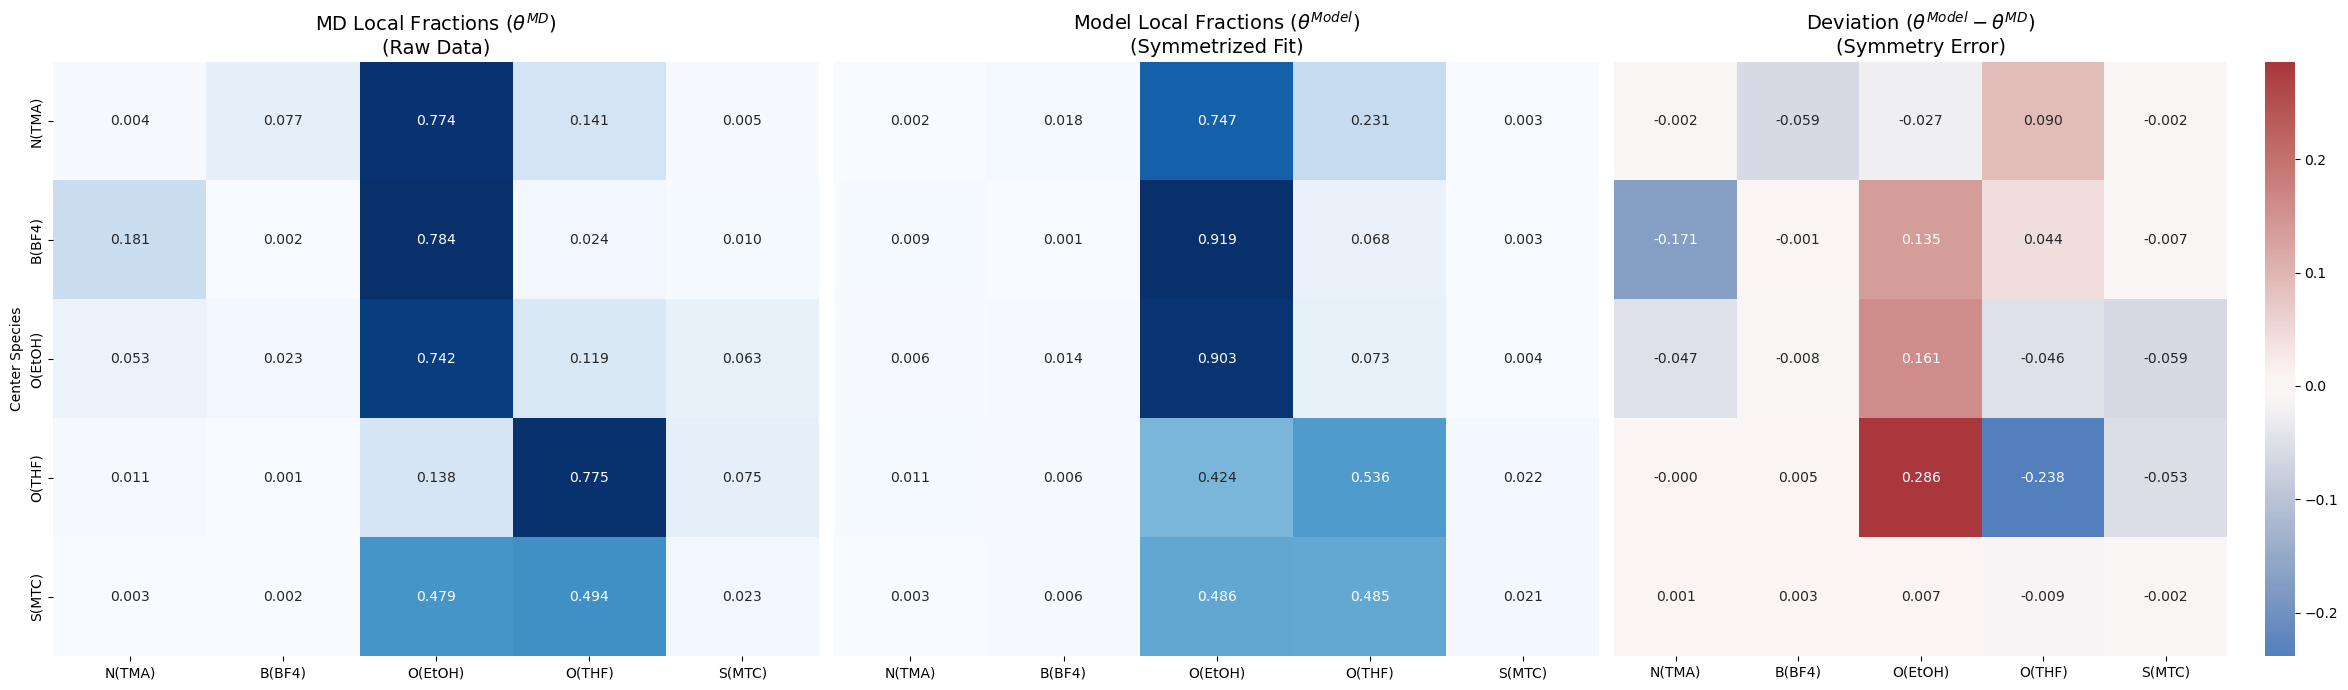

In [16]:

def compare_local_fractions(summary_df, a_matrix, species_order):
    """
    Compares local fractions from raw MD counts vs. Fitted Symmetric Model.
    """
    # 1. Setup Data Structures
    n_species = len(species_order)
    theta_MD = np.zeros((n_species, n_species))
    theta_Model = np.zeros((n_species, n_species))
    
    # Get Global X from summary (assuming consistent)
    X_global = {}
    for idx, row in summary_df.iterrows():
        if row['Neighbor_Species'] not in X_global:
            X_global[row['Neighbor_Species']] = row['X_neighbor']
            
    # Fallback for missing X
    for sp in species_order:
        if sp not in X_global: X_global[sp] = 0.0
    
    X_vec = np.array([X_global[sp] for sp in species_order])
    
    # 2. Compute theta_MD (The "Ground Truth")
    # We need the raw N matrix first
    N_matrix = np.zeros((n_species, n_species))
    
    for idx, row in summary_df.iterrows():
        c = row['Center_Species']
        n = row['Neighbor_Species']
        if c in species_order and n in species_order:
            i = species_order.index(c)
            j = species_order.index(n)
            N_matrix[i, j] = row['CN']
            
    # Apply the same Steric Floor to diagonal N_ii as we did in fitting
    # to ensure fair comparison
    for i in range(n_species):
        if N_matrix[i, i] < 0.01:
            N_matrix[i, i] = 0.01
            
    # Normalize rows to get theta_MD
    row_sums = N_matrix.sum(axis=1, keepdims=True)
    theta_MD = N_matrix / row_sums
    
    # 3. Compute theta_Model (The "Symmetrized Fit")
    # Formula: theta_ji = (X_j * a_ji) / Lambda_i
    
    for i in range(n_species): # Center
        Lambda_i = 0.0
        # Calculate Partition Function Lambda
        for k in range(n_species):
            Lambda_i += X_vec[k] * a_matrix[k, i] # Note: a is symmetric
            
        # Calculate Fractions
        for j in range(n_species): # Neighbor
            theta_Model[i, j] = (X_vec[j] * a_matrix[j, i]) / Lambda_i
            
    # 4. Visualization
    
    # Difference Matrix
    diff_matrix = theta_Model - theta_MD
    
    # Plotting
    fig, axes = plt.subplots(1, 3, figsize=(24, 7))
    
    # Plot A: MD Truth
    sns.heatmap(theta_MD, ax=axes[0], annot=True, fmt=".3f", cmap="Blues",
                xticklabels=species_order, yticklabels=species_order, cbar=False)
    axes[0].set_title("MD Local Fractions ($\\theta^{MD}$)\n(Raw Data)", fontsize=14)
    axes[0].set_ylabel("Center Species")
    
    # Plot B: Model Prediction
    sns.heatmap(theta_Model, ax=axes[1], annot=True, fmt=".3f", cmap="Blues",
                xticklabels=species_order, yticklabels=species_order, cbar=False)
    axes[1].set_title("Model Local Fractions ($\\theta^{Model}$)\n(Symmetrized Fit)", fontsize=14)
    axes[1].set_yticks([]) # Hide Y labels for middle plot
    
    # Plot C: Deviation
    # Red = Model Overpredicts, Blue = Model Underpredicts
    sns.heatmap(diff_matrix, ax=axes[2], annot=True, fmt=".3f", cmap="vlag", center=0,
                xticklabels=species_order, yticklabels=species_order)
    axes[2].set_title("Deviation ($\\theta^{Model} - \\theta^{MD}$)\n(Symmetry Error)", fontsize=14)
    axes[2].set_yticks([])
    
    plt.tight_layout()
    plt.show()
    
    return theta_MD, theta_Model, diff_matrix

# Execute
t_md, t_mod, t_diff = compare_local_fractions(summary_table, a_raw, species_list)

In [17]:
a_raw

array([[1.        , 8.36362017, 4.26152673, 1.77921678, 0.53723367],
       [8.36362017, 1.        , 9.98088769, 1.        , 0.94474457],
       [4.26152673, 9.98088769, 7.53542035, 0.82407415, 1.        ],
       [1.77921678, 1.        , 0.82407415, 1.4071977 , 1.3483183 ],
       [0.53723367, 0.94474457, 1.        , 1.3483183 , 1.35336371]])

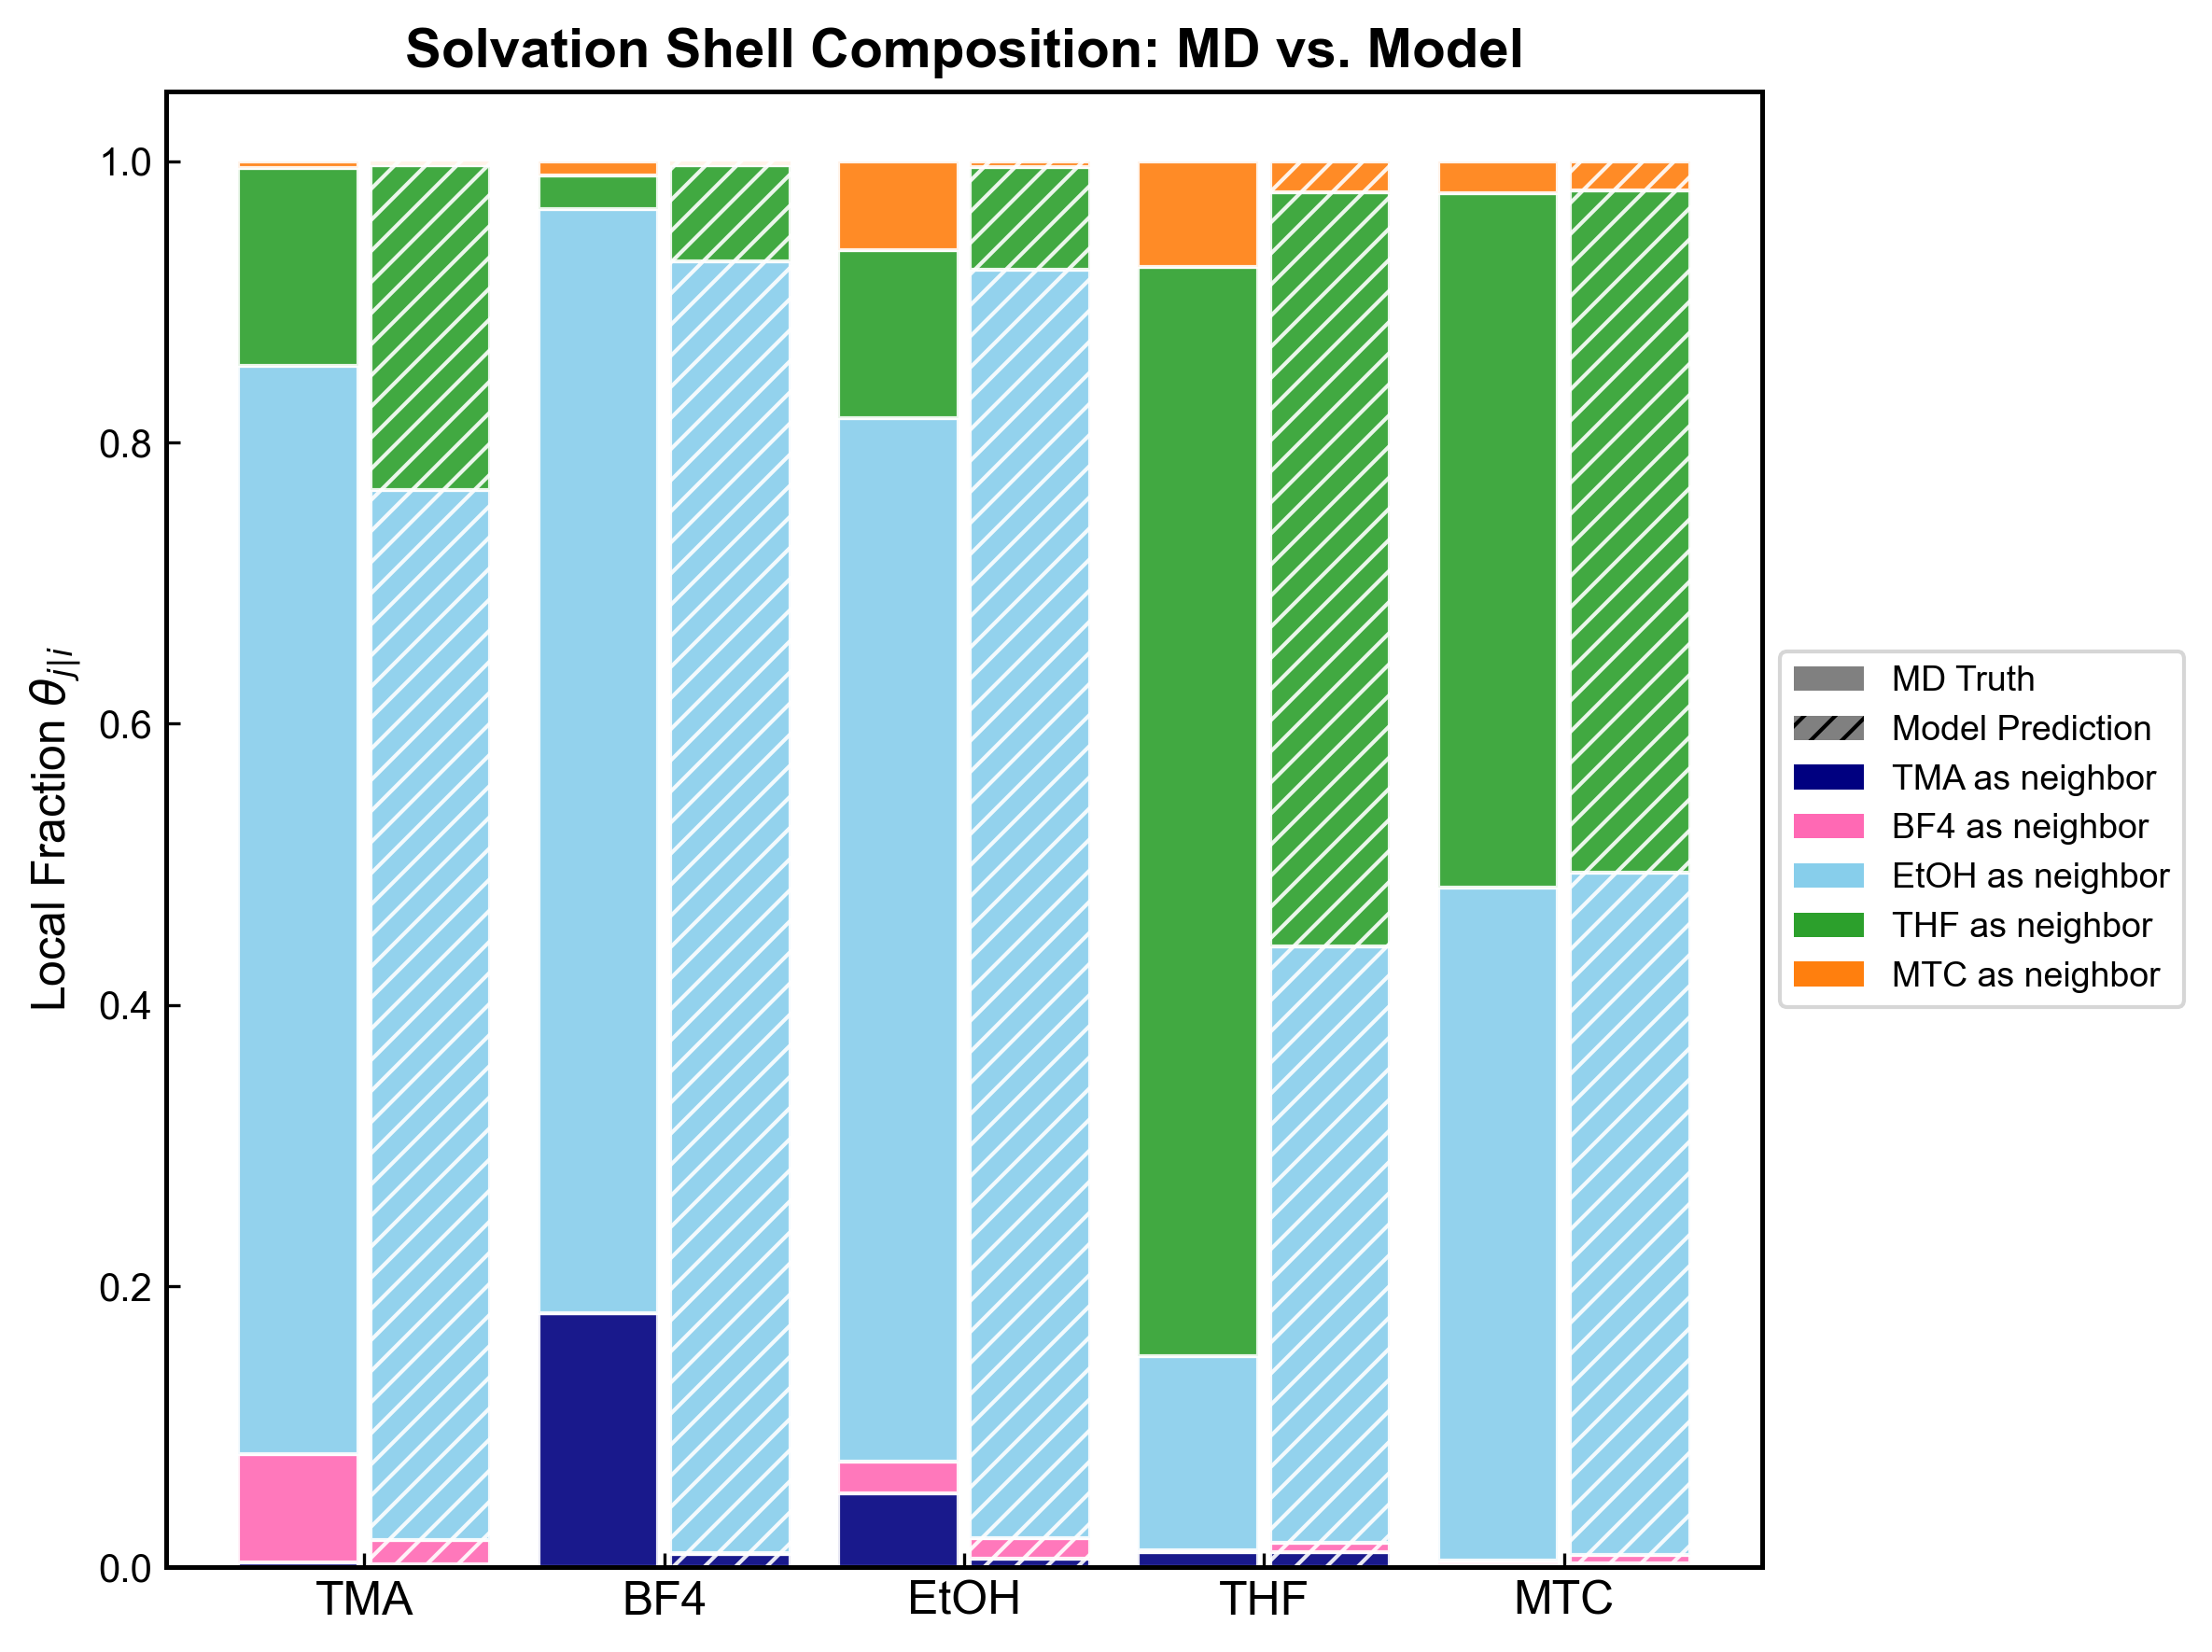

In [54]:
# --- Visualization (Stacked Bar Plot) ---

# Setup
species_labels = ['TMA', 'BF4', 'EtOH', 'THF', 'MTC']
colors = ['navy', 'hotpink', 'skyblue', 'tab:green', 'tab:orange']
n_species = len(species_list)

fig, ax = plt.subplots(figsize=(8, 6))

# X positions
indices = np.arange(n_species)
width = 0.4

# We plot segments for each NEIGHBOR type
# We need to loop over neighbors (0..4) and stack them
bottom_MD = np.zeros(n_species)
bottom_Model = np.zeros(n_species)

for j in range(n_species):
    neighbor_label = species_labels[j]
    color = colors[j]
    
    # Data for this neighbor layer across all centers
    layer_MD = theta_MD[:, j]
    layer_Model = theta_model[:, j]
    
    # Plot MD Bar (Left)
    ax.bar(indices - width/2 - 0.02, layer_MD, width, 
           bottom=bottom_MD, color=color, label=neighbor_label if j==0 else "", edgecolor='white', alpha=0.9)
    
    # Plot Model Bar (Right)
    # We use hatching '//' to distinguish Model from MD
    ax.bar(indices + width/2 + 0.02, layer_Model, width, 
           bottom=bottom_Model, color=color, hatch='///', edgecolor='white', alpha=0.9)
    
    # Update bottoms
    bottom_MD += layer_MD
    bottom_Model += layer_Model

# Custom Legend to explain the Split Bars
# We create dummy handles
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='gray', label='MD Truth'),
                   Patch(facecolor='gray', hatch='///', label='Model Prediction')]

# Add Neighbor Colors to Legend
for j, label in enumerate(species_labels):
    legend_elements.append(Patch(facecolor=colors[j], label=f'{label} as neighbor'))

# Formatting
ax.set_ylabel('Local Fraction $\\theta_{j|i}$', fontsize=12)
ax.set_title('Solvation Shell Composition: MD vs. Model', fontsize=14, fontweight='bold')
ax.set_xticks(indices)
ax.set_xticklabels(species_labels, fontsize=12)
ax.set_ylim(0, 1.05) # Little headroom
# ax.set_xlim(-0.6, n_species - 0.4)

# Add "MD" and "Model" labels under the first group to guide reader
# ax.text(indices[0] - width/2, -0.02, "MD", ha='center', fontsize=10, fontweight='light')
# ax.text(indices[0] + width/2, -0.02, "Model", ha='center', fontsize=10, fontweight='light')

ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.savefig('Solvation_Model_Theta_vsMD.png', dpi=330)
plt.show()

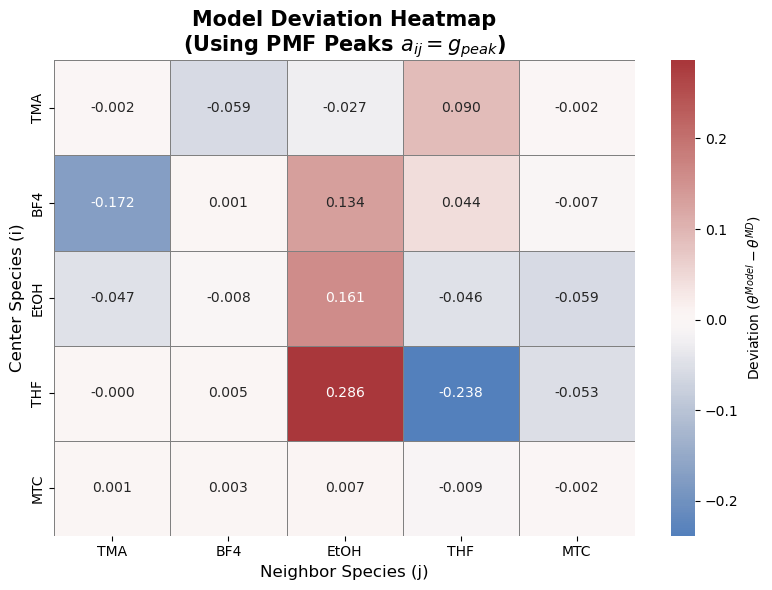

In [23]:
# --- 1. Setup & Data prep ---
# Ensure species list and labels are ready
species_list = ['N(TMA)', 'B(BF4)', 'O(EtOH)', 'O(THF)', 'S(MTC)']
species_labels = ['TMA', 'BF4', 'EtOH', 'THF', 'MTC']
n_species = len(species_list)

# Define Mole Fractions (Global)
# Hardcoded for consistency with your 5-component system
X_dict = {
    'N(TMA)': 0.0067, 'B(BF4)': 0.0067, 
    'O(EtOH)': 0.5568, 'O(THF)': 0.4120, 'S(MTC)': 0.0178
}
X_vec = np.array([X_dict[sp] for sp in species_list])

# --- 2. Calculate Theta_MD (Ground Truth) ---
N_matrix = np.zeros((n_species, n_species))

for idx, row in summary_table.iterrows():
    c = row['Center_Species']
    ne = row['Neighbor_Species']
    
    if c in species_list and ne in species_list:
        i = species_list.index(c)
        j = species_list.index(ne)
        N_matrix[i, j] = row['CN']

# Apply Floor to Self-Coordination (N_ii) to avoid div/0 for ions
# for i in range(n_species):
#     if N_matrix[i, i] < 0.01:
#         N_matrix[i, i] = 0.01

# Normalize rows to get fractions
# axis=1 sums over neighbors (columns) for each center (row)
theta_MD = N_matrix / N_matrix.sum(axis=1, keepdims=True)

# --- 3. Calculate Theta_Model (Using Raw PMF Peaks) ---
a_peak = a_raw
# a_peak = np.zeros((n_species, n_species))

# # Helper to find peak g(r)
# def get_peak_g(s1, s2):
#     # Check Center A - Neighbor B
#     row = summary_table[(summary_table['Center_Species'] == s1) & (summary_table['Neighbor_Species'] == s2)]
#     if not row.empty: return row.iloc[0]['Peak_gr']
#     return np.nan

# for i in range(n_species):
#     for j in range(n_species):
#         sp_i, sp_j = species_list[i], species_list[j]
        
#         # Get peaks from both perspectives
#         p_ij = get_peak_g(sp_i, sp_j)
#         p_ji = get_peak_g(sp_j, sp_i)
        
#         # Symmetrize / Consensus
#         if i == j:
#             # Diagonal
#             val = p_ij
#             a_peak[i, j] = val if not pd.isna(val) else 1.0
#         else:
#             # Off-diagonal average
#             vals = [v for v in [p_ij, p_ji] if not pd.isna(v)]
#             if vals:
#                 a_peak[i, j] = sum(vals) / len(vals)
#             else:
#                 a_peak[i, j] = 1.0 # Random mixing default

# Calculate Model Theta using Local Composition Equation
theta_Model = np.zeros((n_species, n_species))

for i in range(n_species):
    Lambda_i = 0.0
    # Denominator
    for k in range(n_species):
        Lambda_i += X_vec[k] * a_peak[k, i] # a is symmetric
        
    # Numerator & Fraction
    for j in range(n_species):
        theta_Model[i, j] = (X_vec[j] * a_peak[j, i]) / Lambda_i

# --- 4. Plotting the Error Heatmap ---

# Calculate Deviation
error_matrix = theta_Model - theta_MD

# Set up figure
plt.figure(figsize=(8, 6))

# Create Heatmap
# 'vlag' is a good diverging colormap (Blue=Underestimated, Red=Overestimated)
# center=0 ensures white is zero error
sns.heatmap(error_matrix, annot=True, fmt=".3f", cmap="vlag", center=0,
            xticklabels=species_labels, yticklabels=species_labels,
            linewidths=0.5, linecolor='gray',
            cbar_kws={'label': 'Deviation ($\\theta^{Model} - \\theta^{MD}$)'})

plt.title('Model Deviation Heatmap\n(Using PMF Peaks $a_{ij} = g_{peak}$)', fontsize=15, fontweight='bold')
plt.xlabel('Neighbor Species (j)', fontsize=12)
plt.ylabel('Center Species (i)', fontsize=12)

# Save
plt.tight_layout()
plt.savefig('Solvation_Model_Theta_Error_Heatmap.png', dpi=330)
plt.show()

In [55]:
print("a_ij: ",a_peak)

a_ij:  [[1.         8.36362017 4.26152673 1.77921678 0.53723367]
 [8.36362017 1.         9.98088769 1.         0.94474457]
 [4.26152673 9.98088769 7.53542035 0.82407415 1.        ]
 [1.77921678 1.         0.82407415 1.4071977  1.3483183 ]
 [0.53723367 0.94474457 1.         1.3483183  1.35336371]]


# Final Plotting

In [19]:
from matplotlib.patches import Patch

# --- 1. Publication Style ---
def set_pub_style():
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
        'font.size': 10,
        'axes.labelsize': 12,
        'axes.titlesize': 12,
        'legend.fontsize': 9,
        'axes.linewidth': 1.2,
        'lines.linewidth': 2.0,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'figure.dpi': 300
    })

set_pub_style()

# ==========================================
# 2. DATA PREPARATION (REPLACE THIS SECTION)
# ==========================================
# Define Species and Colors
species_5comp = ['TMA$^+$', 'BF$_4^-$', 'EtOH', 'THF', 'MTC']
# Colors: MTC (Red-Substrate), EtOH (Green), THF (Orange), BF4 (Cyan), TMA (Purple)

# --- Panel A: RDF Data Placeholders ---
# If you have your rdf_data loaded, skip this block.
# We create dummy PMF-like curves for TMA+ center
# r_sim = np.linspace(2, 12, 100)
# def make_pmf(r, r0, depth):
#     return depth * (np.exp(-(r-r0)**2/0.2) - 0.1*np.exp(-(r-2*r0)**2/1.0))

# # Synthetic PMF Data (TMA+ Center)
# # Hypothesis: TMA+ recruits MTC (Deepest) and EtOH (Medium), THF is bulk-like
# pmf_data = {
#     'r': r_sim,
#     'MTC':  make_pmf(r_sim, 4.5, -8.0), # Strongest binding
#     'EtOH': make_pmf(r_sim, 4.0, -5.0), # Medium
#     'THF':  make_pmf(r_sim, 4.2, -2.0), # Weak
#     'BF4':  make_pmf(r_sim, 5.0, -4.0)  # Ion pairing
# }

# --- Panel B: Theta Data Placeholders ---
# 5 Components: [TMA, BF4, EtOH, THF, MTC]
# We plot TMA+ and BF4- centers (Rows)
# Columns: [TMA, BF4, EtOH, THF, MTC]
# Synthetic "MD"
# theta_MD_5comp = np.array([
#     [0.0, 0.10, 0.30, 0.20, 0.40], # TMA+ center: Enriched in MTC/EtOH
#     [0.10, 0.0, 0.40, 0.45, 0.05], # BF4- center: Mostly Solvents
# ])
# # Synthetic "Model" (Close match)
# theta_model_5comp = np.array([
#     [0.0, 0.12, 0.28, 0.22, 0.38], 
#     [0.12, 0.0, 0.38, 0.47, 0.03], 
# ])
# ==========================================


In [20]:
rdf_data.columns

Index(['r', 'O(THF)-O(EtOH)', 'O(THF)-O(THF)', 'O(EtOH)-O(EtOH)',
       'N(TMA)-O(EtOH)', 'N(TMA)-O(THF)', 'N(TMA)-S(MTC)', 'N(TMA)-B(BF4)',
       'B(BF4)-O(EtOH)', 'B(BF4)-O(THF)', 'B(BF4)-S(MTC)', 'O(EtOH)-S(MTC)',
       'O(THF)-S(MTC)', 'S(MTC)-S(MTC)', 'N(TMA)-N(TMA)', 'B(BF4)-B(BF4)'],
      dtype='object')

c:\ProgramData\anaconda3\envs\default_env\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


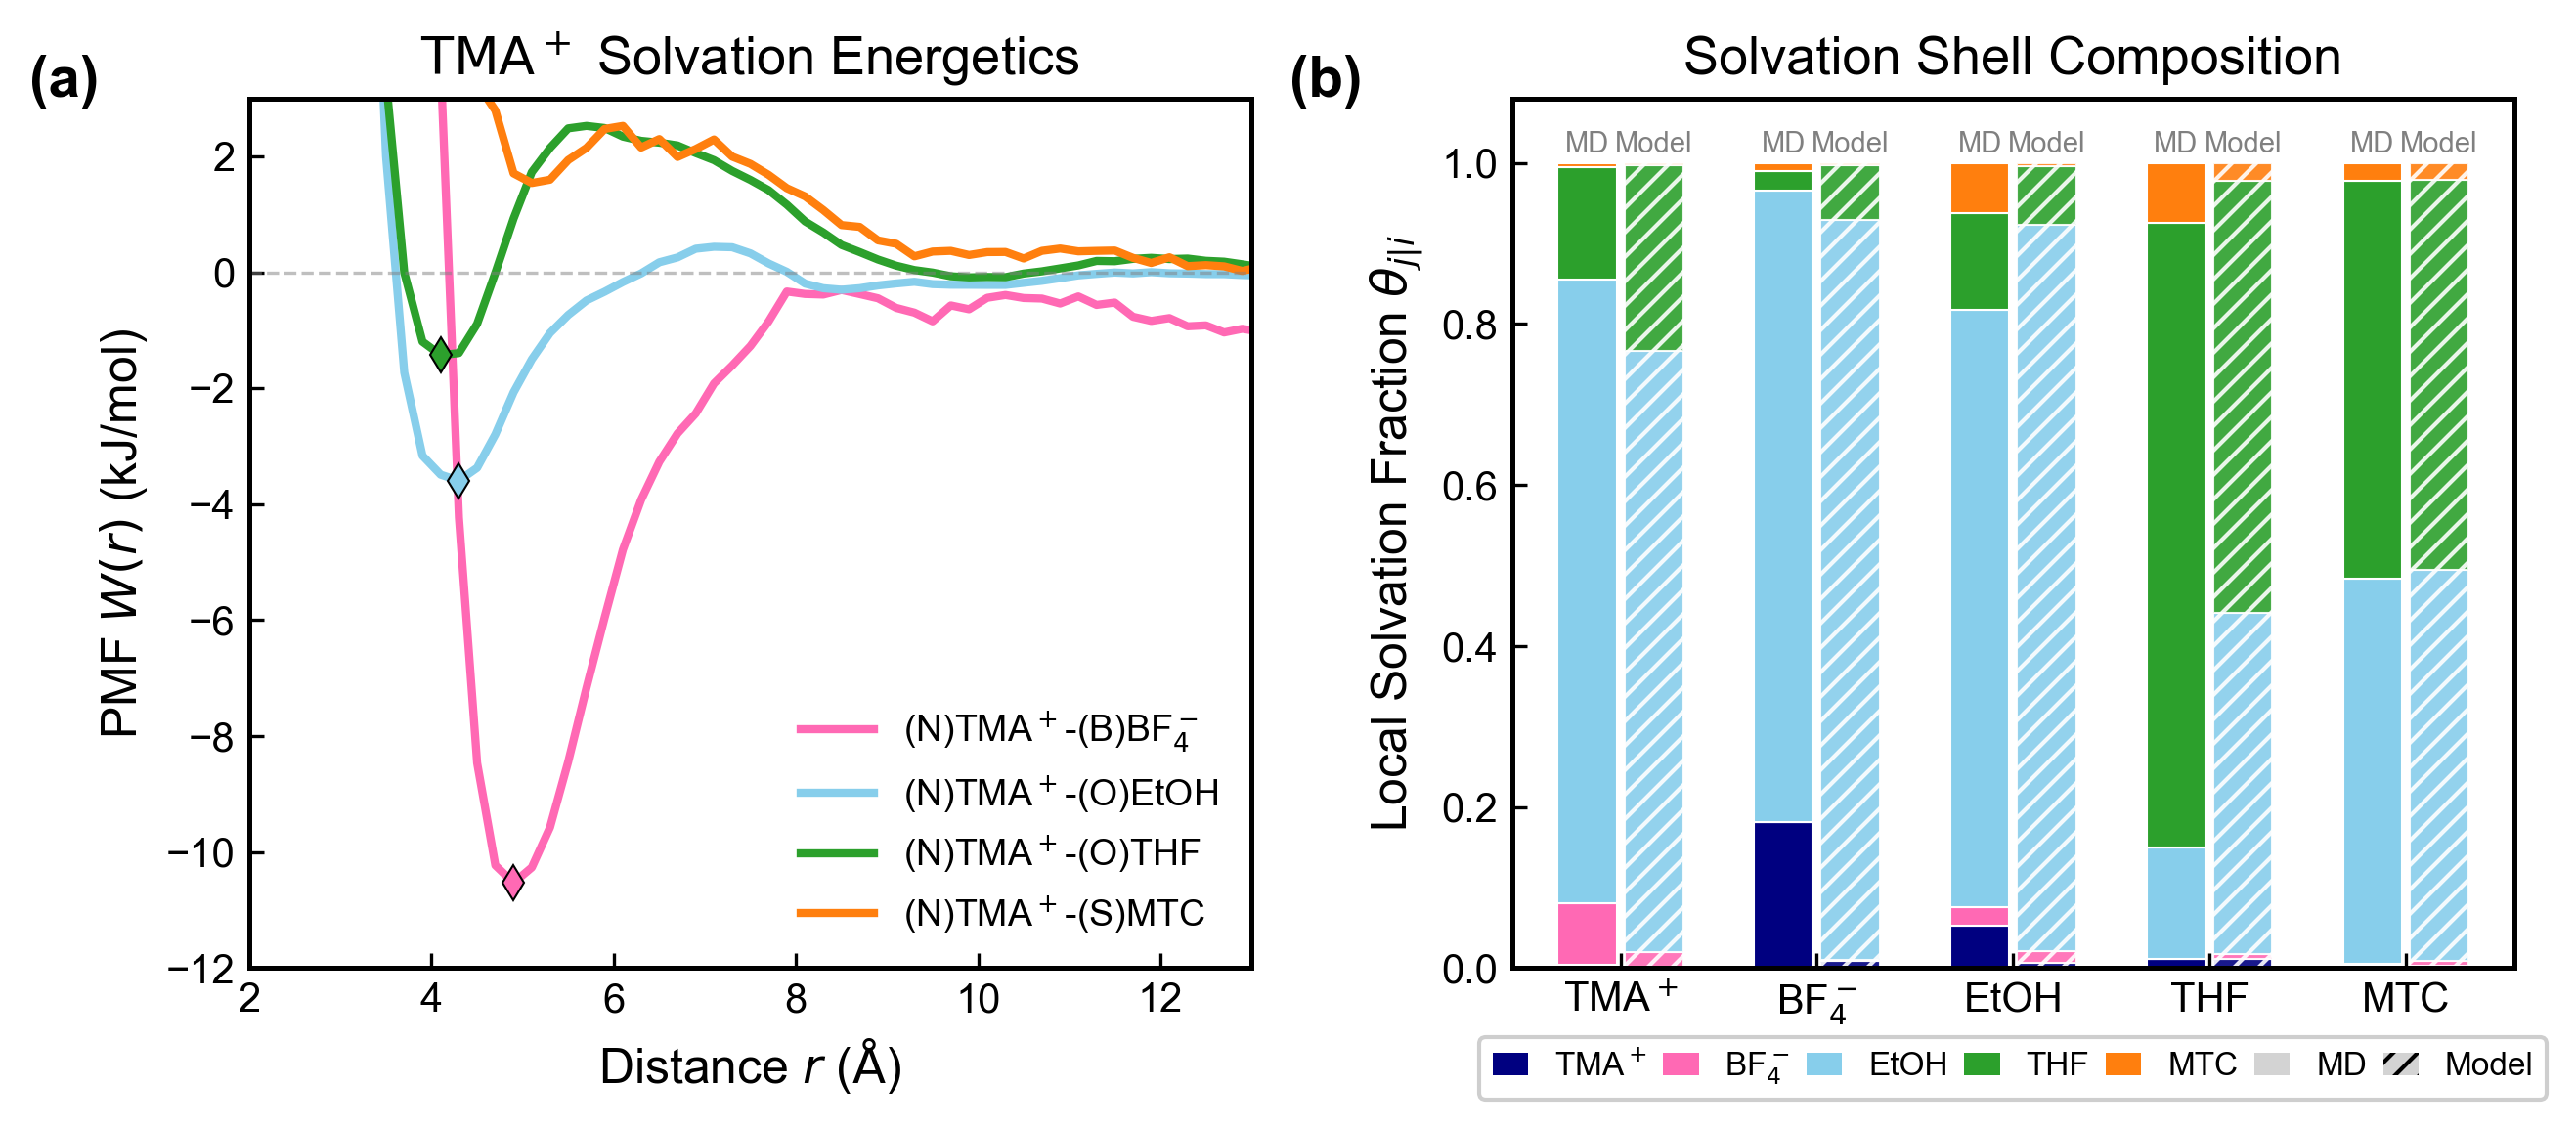

In [ ]:
def set_pub_style():
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
        'font.size': 11,
        'axes.labelsize': 12,
        'axes.titlesize': 13,
        'xtick.labelsize': 10,
        'ytick.labelsize': 10,
        'legend.fontsize': 9,
        'axes.linewidth': 1.2,
        'lines.linewidth': 2.0,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'figure.dpi': 300
    })

set_pub_style()
# --- 3. Plotting Figure 4 ---
fig, axes = plt.subplots(1, 3, figsize=(9, 4))
# plt.subplots_adjust(wspace=0.3)

# ==========================================
# PANEL A: TMA+ Solvation Energetics
# ==========================================
ax = axes[0]
target_center = '(N)TMA$^+$'

# Plot PMF Curves
# Assuming you calculate W(r) from your dataframe
# Here we use the synthetic dictionary 'pmf_data'
# Replace loop with your DataFrame logic: 
# e.g., for neighbor in ['EtOH', 'THF', 'MTC']: plot(rdf_data['r'], -kT*log(rdf_data[col]))

neighbors_to_plot = ['B(BF4)', 'O(EtOH)', 'O(THF)', 'S(MTC)'] # Focus on neutrals
column_name_map = {'B(BF4)': 'N(TMA)-B(BF4)',
                   'O(EtOH)': 'N(TMA)-O(EtOH)',
                     'O(THF)': 'N(TMA)-O(THF)',
                        'S(MTC)': 'N(TMA)-S(MTC)'}

legend_map = {'B(BF4)': '(B)BF$_4^-$',
                   'O(EtOH)': '(O)EtOH',
                        'O(THF)': '(O)THF',
                            'S(MTC)': '(S)MTC'}

for neighbor in neighbors_to_plot:
    # Get Data (Replace with your actual data extraction)
    
    w = -R_gas * T_sys * np.log(rdf_data[column_name_map[neighbor]])/1000 # PMF from RDF  kJ/mol
    r = rdf_data['r']
    color = SPECIES_COLOR[neighbor]
    ax.plot(r, w, color=color, label=f'{target_center}-{legend_map[neighbor]}')
    
    # Annotate Minimum
    min_idx = np.argmin(w)
    ax.plot(r[min_idx], w[min_idx], marker='d', color=color, 
            markeredgecolor='black', markeredgewidth=0.5, markersize=6)

ax.set_xlim(2, 13)
ax.set_ylim(-12, 3)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
ax.set_xlabel(r"Distance $r$ ($\mathrm{\AA}$)")
ax.set_ylabel(r"PMF $W(r)$ (kJ/mol)")
ax.set_title(r"$\mathrm{TMA}^+$ Solvation Energetics")

# Legend with specific layout
ax.legend(frameon=False, loc='lower right', fontsize=9)
ax.text(-0.15, 1.05, "(a)", transform=ax.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

# ==========================================
# PANEL B: Solvation Shell Composition
# ==========================================
ax = axes[1]

species_labels = ['TMA$^+$', 'BF$_4^-$', 'EtOH', 'THF', 'MTC']
colors = ['navy', 'hotpink', 'skyblue', 'tab:green', 'tab:orange']
n_species = len(species_list)



x_pos = np.arange(len(species_list)) * 1.5 # Spacing
width = 0.45

bottom_MD = np.zeros(len(species_list))
bottom_Model = np.zeros(len(species_list))

# Loop over Neighbors (Stack layers)
for j, comp in enumerate(species_list):
    # Data slices
    # Replace theta_MD_5comp with your actual theta_MD array
    # Ensure dimensions match: [n_centers, n_neighbors]
    layer_MD = theta_MD[:, j]
    layer_Model = theta_model[:, j]
    
    c = SPECIES_COLOR[species_list[j]]
    
    # MD Bar
    ax.bar(x_pos - width/2 - 0.03, layer_MD, width, bottom=bottom_MD, 
           color=c, edgecolor='white', linewidth=0.5)
    
    # Model Bar
    ax.bar(x_pos + width/2 + 0.03, layer_Model, width, bottom=bottom_Model, 
           color=c, hatch='////', edgecolor='white', linewidth=0.5, alpha=0.9)
    
    bottom_MD += layer_MD
    bottom_Model += layer_Model

ax.set_xticks(x_pos)
ax.set_xticklabels(species_labels)
ax.set_ylabel(r"Local Solvation Fraction $\theta_{j|i}$")
ax.set_title("Solvation Shell Composition")
ax.set_ylim(0, 1.08)

# MD/Model Labels
for x in x_pos:
    ax.text(x - width/2 - 0.03, 1.04, "MD", ha='center', va='top', fontsize=7, color='gray')
    ax.text(x + width/2 + 0.03, 1.04, "Model", ha='center', va='top', fontsize=7, color='gray')

# Legend (Outside Right or Top)
# Creating a custom legend handles list
handles = []
for j, label in enumerate(species_labels):
    handles.append(Patch(facecolor=colors[j], label=f'{label}'))
handles.append(Patch(facecolor='lightgray', label='MD'))
handles.append(Patch(facecolor='lightgray', hatch='////', label='Model'))

ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.17), framealpha=0.95,
          ncol=len(handles), frameon=True, fontsize=8, handlelength=1.1, columnspacing=0.5)
ax.text(-0.15, 1.05, "(b)", transform=ax.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

# --- Save ---
plt.tight_layout()
plt.savefig('Figure_4_5Comp_Thermodynamics.png', dpi=300, bbox_inches='tight')
plt.show()

c:\ProgramData\anaconda3\envs\default_env\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


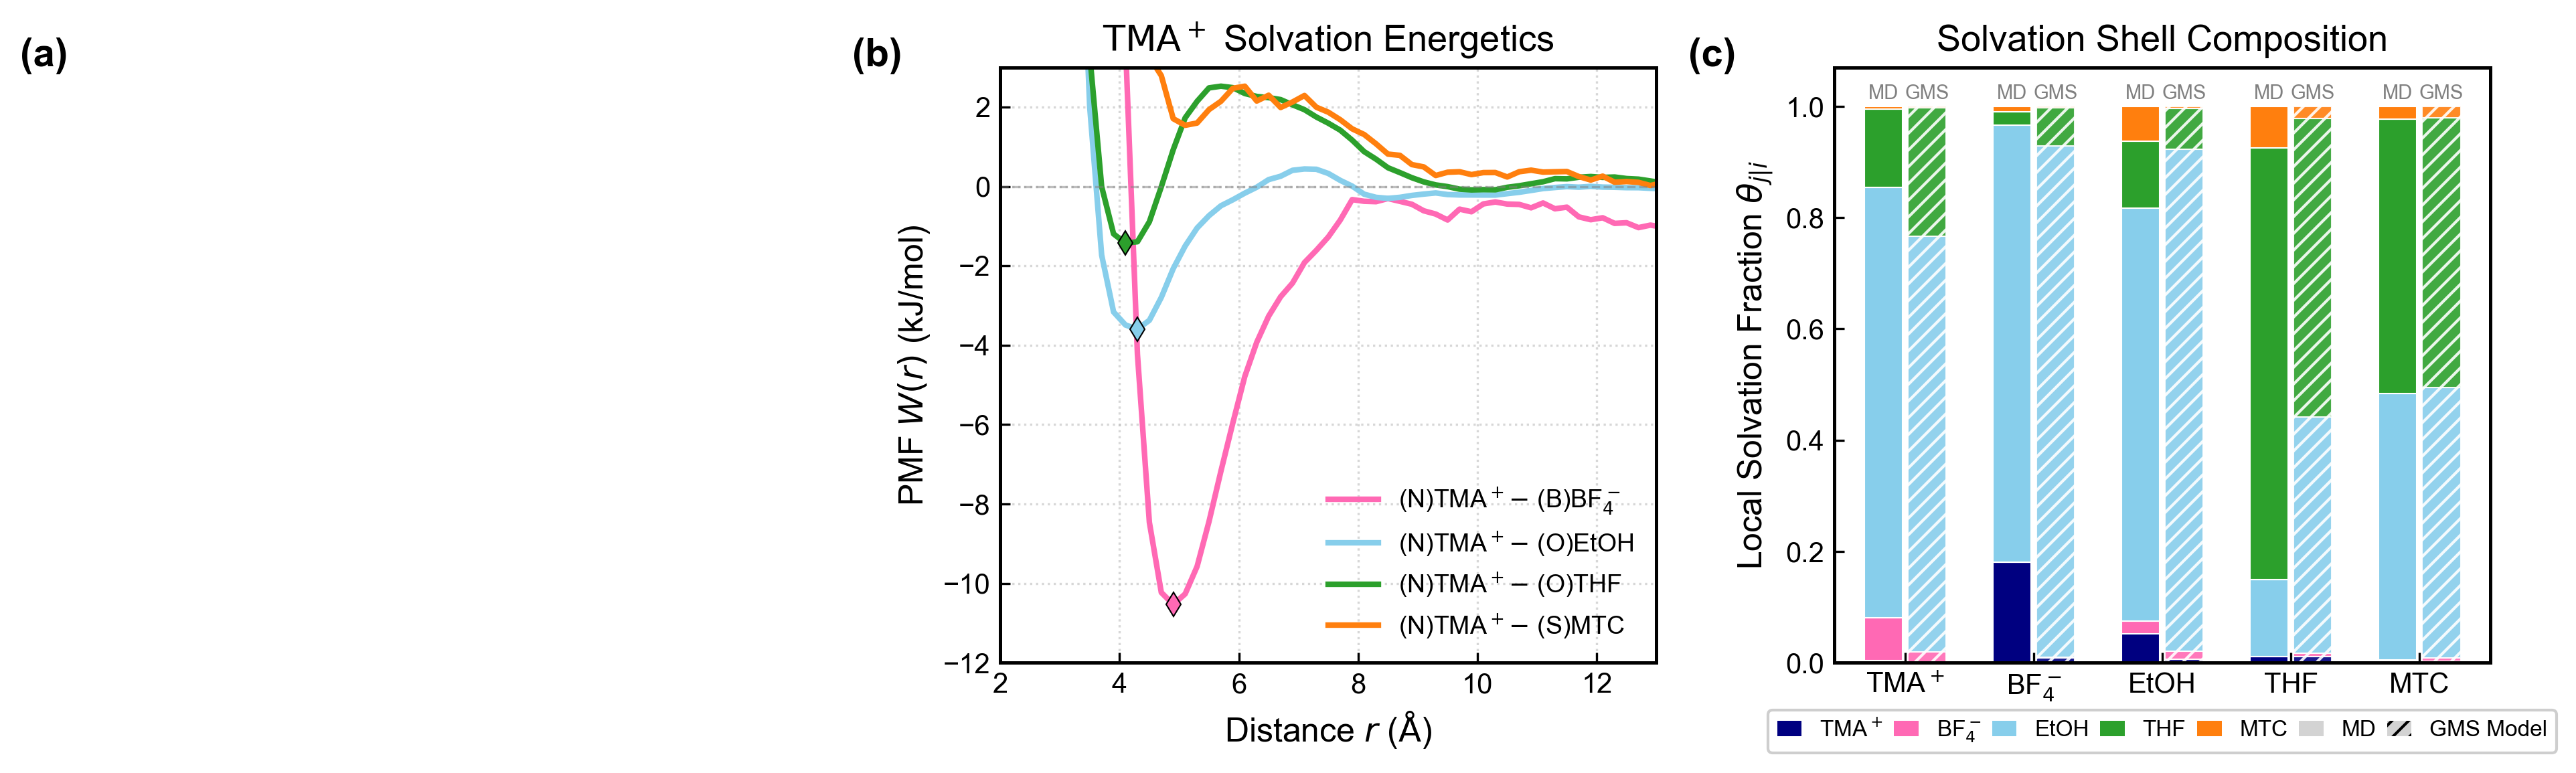

In [21]:
def set_pub_style():
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
        'font.size': 11,
        'axes.labelsize': 12,
        'axes.titlesize': 13,
        'xtick.labelsize': 10,
        'ytick.labelsize': 10,
        'legend.fontsize': 9,
        'axes.linewidth': 1.2,
        'lines.linewidth': 2.0,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'figure.dpi': 300
    })

set_pub_style()
# --- 3. Plotting Figure 4 ---
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
plt.subplots_adjust(wspace=0.1) # Space between panels

# ==========================================
# PANEL A: Molecular Structures
# ==========================================
ax = axes[0]
ax.axis('off')
# ax.text(0.5, 0.5, "Insert Molecular\nStructures Here\n(Materials Studio/Vesta)", 
#         ha='center', va='center', fontsize=12, color='gray')
ax.text(-0.15, 1.05, "(a)", transform=ax.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

# ==========================================
# PANEL B: TMA+ Solvation Energetics
# ==========================================
ax = axes[1]
target_center = '(N)TMA$^+$'

# Plot PMF Curves
# Assuming you calculate W(r) from your dataframe
# Here we use the synthetic dictionary 'pmf_data'
# Replace loop with your DataFrame logic: 
# e.g., for neighbor in ['EtOH', 'THF', 'MTC']: plot(rdf_data['r'], -kT*log(rdf_data[col]))

neighbors_to_plot = ['B(BF4)', 'O(EtOH)', 'O(THF)', 'S(MTC)'] # Focus on neutrals
column_name_map = {'B(BF4)': 'N(TMA)-B(BF4)',
                   'O(EtOH)': 'N(TMA)-O(EtOH)',
                     'O(THF)': 'N(TMA)-O(THF)',
                        'S(MTC)': 'N(TMA)-S(MTC)'}

legend_map = {'B(BF4)': '(B)BF$_4^-$',
                   'O(EtOH)': '(O)EtOH',
                        'O(THF)': '(O)THF',
                            'S(MTC)': '(S)MTC'}

for neighbor in neighbors_to_plot:
    # Get Data (Replace with your actual data extraction)
    
    w = -R_gas * T_sys * np.log(rdf_data[column_name_map[neighbor]])/1000 # PMF from RDF  kJ/mol
    r = rdf_data['r']
    color = SPECIES_COLOR[neighbor]
    ax.plot(r, w, color=color, label=f'{target_center}$-$ {legend_map[neighbor]}')
    
    # Annotate Minimum
    min_idx = np.argmin(w)
    ax.plot(r[min_idx], w[min_idx], marker='d', color=color, 
            markeredgecolor='black', markeredgewidth=0.5, markersize=6)

ax.grid(True, linestyle=':', alpha=0.5)
ax.set_xlim(2, 13)
ax.set_ylim(-12, 3)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
ax.set_xlabel(r"Distance $r$ ($\mathrm{\AA}$)")
ax.set_ylabel(r"PMF $W(r)$ (kJ/mol)")
ax.set_title(r"$\mathrm{TMA}^+$ Solvation Energetics")

# Legend with specific layout
ax.legend(frameon=False, loc='lower right', fontsize=9)
ax.text(-0.15, 1.05, "(b)", transform=ax.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

# ==========================================
# PANEL C: Solvation Shell Composition
# ==========================================
ax = axes[2]

species_labels = ['TMA$^+$', 'BF$_4^-$', 'EtOH', 'THF', 'MTC']
colors = ['navy', 'hotpink', 'skyblue', 'tab:green', 'tab:orange']
n_species = len(species_list)



x_pos = np.arange(len(species_list)) * 1.5 # Spacing
width = 0.45

bottom_MD = np.zeros(len(species_list))
bottom_Model = np.zeros(len(species_list))

# Loop over Neighbors (Stack layers)
for j, comp in enumerate(species_list):
    # Data slices
    # Replace theta_MD_5comp with your actual theta_MD array
    # Ensure dimensions match: [n_centers, n_neighbors]
    layer_MD = theta_MD[:, j]
    layer_Model = theta_model[:, j]
    
    c = SPECIES_COLOR[species_list[j]]
    
    # MD Bar
    ax.bar(x_pos - width/2 - 0.03, layer_MD, width, bottom=bottom_MD, 
           color=c, edgecolor='white', linewidth=0.5)
    
    # Model Bar
    ax.bar(x_pos + width/2 + 0.03, layer_Model, width, bottom=bottom_Model, 
           color=c, hatch='////', edgecolor='white', linewidth=0.5, alpha=0.9)
    
    bottom_MD += layer_MD
    bottom_Model += layer_Model

ax.set_xticks(x_pos)
ax.set_xticklabels(species_labels)
ax.set_ylabel(r"Local Solvation Fraction $\theta_{j|i}$")
ax.set_title("Solvation Shell Composition")
ax.set_ylim(0, 1.07)

# MD/Model Labels
for x in x_pos:
    ax.text(x - width/2 - 0.03, 1.04, "MD", ha='center', va='top', fontsize=7, color='gray')
    ax.text(x + width/2 + 0.03, 1.04, "GMS", ha='center', va='top', fontsize=7, color='gray')

# Legend (Outside Right or Top)
# Creating a custom legend handles list
handles = []
for j, label in enumerate(species_labels):
    handles.append(Patch(facecolor=colors[j], label=f'{label}'))
handles.append(Patch(facecolor='lightgray', label='MD'))
handles.append(Patch(facecolor='lightgray', hatch='////', label='GMS Model'))

ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.17), framealpha=0.95,
          ncol=len(handles), frameon=True, fontsize=8, handlelength=1.1, columnspacing=0.5)
ax.text(-0.15, 1.05, "(c)", transform=ax.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

# --- Save ---
plt.tight_layout()
# plt.savefig('Figure_4_5Comp_Thermodynamics_1x3.png', dpi=300, bbox_inches='tight')
plt.show()

c:\ProgramData\anaconda3\envs\default_env\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


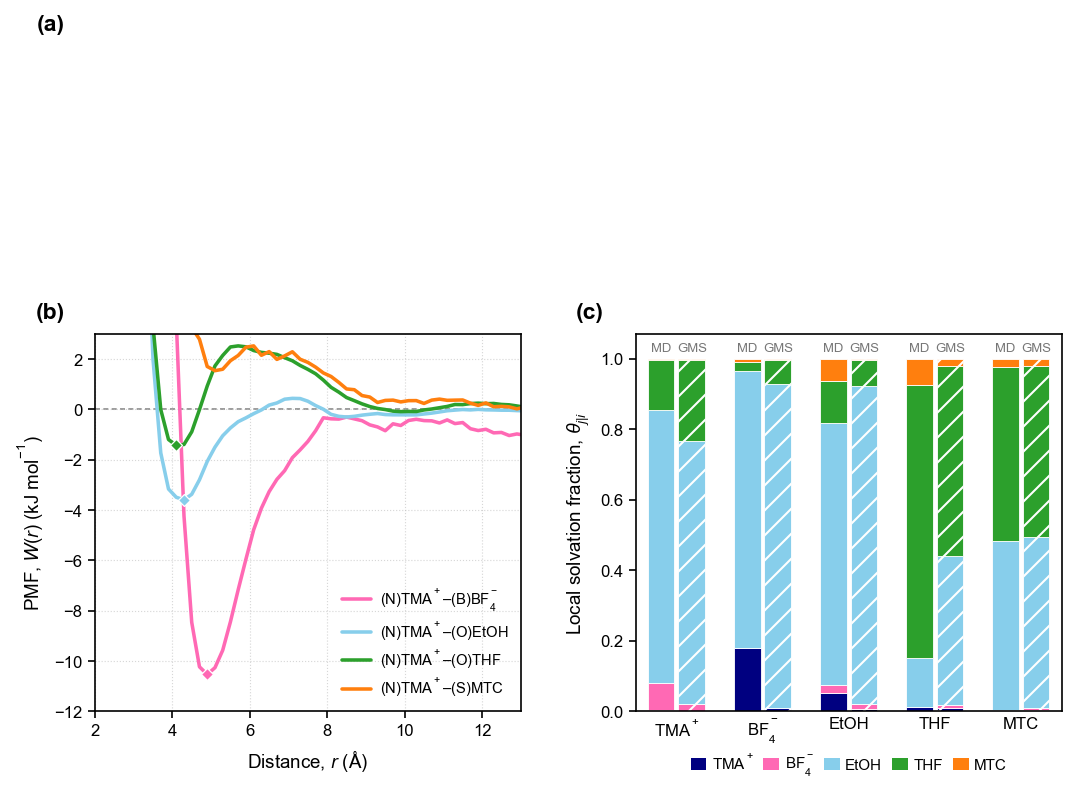

In [33]:
# ============================================================
# FIGURE 4: JACS-STYLE FULL-WIDTH 1 + 2 LAYOUT
# ============================================================

# ------------------------------------------------------------
# 1. PUBLICATION STYLE
# ------------------------------------------------------------
def set_pub_style():
    """Set consistent styling for manuscript figures."""

    plt.rcParams.update({
        # Font
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 8.5,
        "axes.labelsize": 9,
        "axes.titlesize": 9.5,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 7.3,

        # Axes and lines
        "axes.linewidth": 0.8,
        "lines.linewidth": 1.7,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "xtick.major.size": 3.5,
        "ytick.major.size": 3.5,
        "xtick.direction": "out",
        "ytick.direction": "out",

        # Notebook display and export
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,

        # Mathematical text
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
    })


def style_axis(ax, grid=False):
    """Apply uniform axis styling."""

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        top=False,
        right=False,
        pad=2.5
    )

    if grid:
        ax.grid(
            True,
            which="major",
            linestyle=":",
            linewidth=0.55,
            color="#BDBDBD",
            alpha=0.60
        )
        ax.set_axisbelow(True)


def add_panel_label(ax, label, x=-0.14, y=1.03):
    """Add consistent multipanel labels."""

    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        clip_on=False
    )


set_pub_style()


# ------------------------------------------------------------
# 2. FIGURE LAYOUT
# ------------------------------------------------------------
# Full-width figure:
#   panel (a) spans the upper row
#   panels (b) and (c) occupy the lower row
fig = plt.figure(figsize=(7.2, 5.25))

gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    height_ratios=[0.72, 1.28],
    width_ratios=[1.0, 1.0],
    left=0.09,
    right=0.985,
    bottom=0.11,
    top=0.975,
    wspace=0.27,
    hspace=0.31
)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])


# ============================================================
# PANEL A: MOLECULAR STRUCTURES
# ============================================================
ax = ax_a
ax.axis("off")

# Suggested arrangement:
#
#       TMA+       BF4−       EtOH       THF       MTC
#      [image]    [image]    [image]    [image]    [image]
#
# Place the atom-color key in a compact row beneath the structures.
# Existing structure-placement coordinates will need to be adjusted
# for this full-width axis.

add_panel_label(ax, "(a)", x=-0.06, y=0.98)


# ============================================================
# PANEL B: TMA+ SOLVATION ENERGETICS
# ============================================================
ax = ax_b

neighbors_to_plot = [
    "B(BF4)",
    "O(EtOH)",
    "O(THF)",
    "S(MTC)"
]

column_name_map = {
    "B(BF4)": "N(TMA)-B(BF4)",
    "O(EtOH)": "N(TMA)-O(EtOH)",
    "O(THF)": "N(TMA)-O(THF)",
    "S(MTC)": "N(TMA)-S(MTC)"
}

# Keep the TMA+ center explicitly in every legend entry,
# consistent with the Li+ PMF legend in Figure 3.
legend_map = {
    "B(BF4)":  r"(N)TMA$^+$–(B)BF$_4^-$",
    "O(EtOH)": r"(N)TMA$^+$–(O)EtOH",
    "O(THF)":  r"(N)TMA$^+$–(O)THF",
    "S(MTC)":  r"(N)TMA$^+$–(S)MTC"
}


for neighbor in neighbors_to_plot:

    # --------------------------------------------------------
    # Original PMF calculation: unchanged
    # --------------------------------------------------------
    w = (
        -R_gas
        * T_sys
        * np.log(rdf_data[column_name_map[neighbor]])
        / 1000
    )

    r = rdf_data["r"]
    color = SPECIES_COLOR[neighbor]

    ax.plot(
        r,
        w,
        color=color,
        linewidth=1.7,
        label=legend_map[neighbor],
        solid_capstyle="round"
    )

    # --------------------------------------------------------
    # Original minimum identification: unchanged
    # --------------------------------------------------------
    min_idx = np.argmin(w)

    # Robust indexing for either pandas Series or NumPy arrays
    min_r = r.iloc[min_idx] if hasattr(r, "iloc") else r[min_idx]
    min_w = w.iloc[min_idx] if hasattr(w, "iloc") else w[min_idx]

    ax.plot(
        min_r,
        min_w,
        marker="D",
        markersize=4.3,
        markerfacecolor=color,
        markeredgecolor="white",
        markeredgewidth=0.6,
        linestyle="none",
        zorder=4
    )


# Zero-PMF reference line
ax.axhline(
    0,
    color="#777777",
    linestyle=(0, (3, 2)),
    linewidth=0.8,
    alpha=0.85,
    zorder=0
)

# Original limits: unchanged
ax.set_xlim(2, 13)
ax.set_ylim(-12, 3)

ax.set_xlabel(r"Distance, $r$ ($\mathrm{\AA}$)")
ax.set_ylabel(r"PMF, $W(r)$ (kJ mol$^{-1}$)")

# Keep or remove this title consistently with Figure 3.
# If Figure 3 retains panel titles, uncomment this line.
#
# ax.set_title(r"TMA$^+$ solvation energetics", pad=5)

ax.legend(
    frameon=False,
    loc="lower right",
    fontsize=7.1,
    handlelength=2.0,
    handletextpad=0.55,
    labelspacing=0.32,
    borderaxespad=0.45
)

style_axis(ax, grid=True)
add_panel_label(ax, "(b)")


# ============================================================
# PANEL C: SOLVATION-SHELL COMPOSITION
# ============================================================
ax = ax_c

species_labels = [
    r"TMA$^+$",
    r"BF$_4^-$",
    "EtOH",
    "THF",
    "MTC"
]

n_species = len(species_list)

# Greater spacing between center-species groups than between
# the MD and GMS bars within each pair
group_spacing = 1.10
x_pos = np.arange(n_species) * group_spacing

width = 0.34
pair_gap = 0.025

x_md = x_pos - width / 2 - pair_gap
x_gms = x_pos + width / 2 + pair_gap

bottom_MD = np.zeros(n_species)
bottom_Model = np.zeros(n_species)


for j, comp in enumerate(species_list):

    # Original plotted values: unchanged
    layer_MD = theta_MD[:, j]
    layer_Model = theta_model[:, j]

    color = SPECIES_COLOR[species_list[j]]

    # MD bars: solid
    ax.bar(
        x_md,
        layer_MD,
        width=width,
        bottom=bottom_MD,
        color=color,
        edgecolor="white",
        linewidth=0.40
    )

    # GMS bars: hatched
    ax.bar(
        x_gms,
        layer_Model,
        width=width,
        bottom=bottom_Model,
        color=color,
        hatch="//",
        edgecolor="white",
        linewidth=0.40
    )

    bottom_MD += layer_MD
    bottom_Model += layer_Model


ax.set_xlim(
    x_pos[0] - 0.52,
    x_pos[-1] + 0.52
)

ax.set_ylim(0, 1.07)

ax.set_xticks(x_pos)
ax.set_xticklabels(species_labels)
ax.tick_params(axis="x", length=0)

ax.set_ylabel(r"Local solvation fraction, $\theta_{j|i}$")

# Uncomment if Figure 3 retains corresponding panel titles.
#
# ax.set_title("Solvation-shell composition", pad=5)


# MD/GMS labels above each paired bar
for x1, x2 in zip(x_md, x_gms):

    ax.text(
        x1,
        1.012,
        "MD",
        ha="center",
        va="bottom",
        fontsize=6.3,
        color="#777777"
    )

    ax.text(
        x2,
        1.012,
        "GMS",
        ha="center",
        va="bottom",
        fontsize=6.3,
        color="#777777"
    )


# Species-color legend
species_handles = [
    Patch(
        facecolor=SPECIES_COLOR[species_list[j]],
        edgecolor="none",
        label=species_labels[j]
    )
    for j in range(n_species)
]

ax.legend(
    handles=species_handles,
    loc="upper center",
    bbox_to_anchor=(0.50, -0.09),
    ncol=5,
    frameon=False,
    handlelength=1.05,
    handleheight=0.8,
    handletextpad=0.35,
    columnspacing=0.65,
    borderaxespad=0
)

# Because each pair is already labeled MD/GMS above the bars,
# a separate gray method legend is unnecessary.

style_axis(ax, grid=False)
add_panel_label(ax, "(c)")


# ------------------------------------------------------------
# 3. DISPLAY
# ------------------------------------------------------------



# ------------------------------------------------------------
# 4. EXPORT
# ------------------------------------------------------------
# Vector PDF:
#
# fig.savefig(
#     "Figure_4_5Comp_Thermodynamics_JACS.pdf",
#     bbox_inches="tight",
#     pad_inches=0.02
# )

# High-resolution TIFF:
#
# fig.savefig(
#     "Figure_4_5Comp_Thermodynamics_JACS.tif",
#     dpi=600,
#     bbox_inches="tight",
#     pad_inches=0.02,
#     pil_kwargs={"compression": "tiff_lzw"}
# )

plt.savefig('Figure_4_Revised_1+2.png', dpi=500, bbox_inches='tight')
plt.show()

## Dynamics Plotting

In [34]:
from matplotlib.ticker import ScalarFormatter

# ==========================================
# 1. PUBLICATION STYLE SETTINGS
# ==========================================
def set_pub_style():
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
        'font.size': 10,
        'axes.labelsize': 11,
        'axes.titlesize': 12,
        'legend.fontsize': 8,  # Slightly smaller for detailed legends
        'axes.linewidth': 1.0,
        'lines.linewidth': 1.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'figure.dpi': 300
    })

set_pub_style()


In [35]:

# ==========================================
# 2. DATA LOADING & PROCESSING
# ==========================================

# --- Load Panel A Data (MD) ---
try:
    df_md = pd.read_csv("EtOH_THF_ratio_surface_0-10A_0.1M.csv")
except FileNotFoundError:
    print("Warning: MD file not found. Please ensure 'EtOH_THF_ratio_surface_0-10A_0.1M.csv' is in the directory.")
    df_md = pd.DataFrame()

# --- Load Panel B Data (COMSOL L=5nm) ---

# --- Load Panel B Data (COMSOL L=5nm) ---
try:
    # Skip first 4 lines of comments usually found in COMSOL CSVs
    df_b = pd.read_csv("COMSOL_OHP_EtOH-THF_L=5nm.csv", skiprows=4)
    # Clean column names (remove units/extra text)
    df_b.columns = ['phi_solid', 'Time', 'Surface_Charge', 'Ratio_OHP', 'cEtOH', 'cTHF', 'cMTC', 'cCat', 'cAni']
except FileNotFoundError:
    print("Warning: COMSOL Panel B file not found.")
    df_b = pd.DataFrame()

# --- Load Panel C & D Data (COMSOL Variable L) ---
results_scaling = []
try:
    df_c = pd.read_csv("COMSOL_OHP_concentration_phi1.6V.csv", skiprows=4)
    
    # Helper to clean column names
    def clean_col(name):
        if "L_cell" in name: return "L_cell"
        if "Time" in name: return "Time"
        if "cEtOH" in name: return "cEtOH"
        return name
    df_c.columns = [clean_col(c) for c in df_c.columns]
    
    # Process each L_cell
    unique_L = sorted(df_c['L_cell'].unique())
    
    for L in unique_L:
        # Get data for this L, sorted by time
        df_L = df_c[df_c['L_cell'] == L].sort_values('Time')
        time = df_L['Time'].values  # ms
        conc = df_L['cEtOH'].values # mol/L


        # --- Calculate RC time = lambda_D*L_cell/((DCat+DAni)/2) ---
        DCat = 4.183E-10  # m^2/s (TMA+)
        DAni = 4.075E-10  # m^2/s (BF4-)
        lambda_D = 4.343E-10 # m (Debye length at 0.1M)
        L_m = L * 1e-3   # Convert nm to m
        rc_time_s = (lambda_D * L_m) / ((DCat + DAni)/2)  # seconds
        rc_time_ms = rc_time_s * 1e3  # ms

        print(f"L={L} nm: RC time = {rc_time_ms:.2f} ms.")
        
        # --- Calculate Characteristic Time (Tau) ---
        # Definition: Time to reach 95% of the steady-state change
        tau = 0.0
        if len(time) > 1:
            c_start = conc[0]
            c_final = conc[-1]
            total_change = c_final - c_start
            
            # Only calculate if there is a meaningful change
            if abs(total_change) > 1e-6:
                # Find indices where deviation is within 1% of total change
                deviation = np.abs(conc - c_final)
                threshold = 0.05 * np.abs(total_change)
                settled_indices = np.where(deviation < threshold)[0]
                
                if len(settled_indices) > 0:
                    # Robustly find the start of the settled region
                    idx_tau = settled_indices[-1]
                    for i in range(len(settled_indices)-1, 0, -1):
                        if settled_indices[i] - settled_indices[i-1] == 1:
                            idx_tau = settled_indices[i-1]
                        else:
                            break
                    tau = time[idx_tau]
                    print(f"L={L} nm settled at tau = {tau:.2f} ms.")
                else:
                    tau = time[-1] # Didn't settle
                    print(f"Warning: L={L} nm did not settle within simulation time.")
        
        results_scaling.append({
            'L_mm': L,
            'L_m': L * 1e-3,
            'tau_RC_ms': rc_time_ms,
            'tau_RC_s': rc_time_s,
            'tau_ms': tau,
            'tau_s': tau * 1e-3,
            'time': time,
            'conc': conc
        })
        
except FileNotFoundError:
    print("Warning: COMSOL Panel C/D file not found.")

# save results_scaling to DataFrame and then CSV
df_scaling = pd.DataFrame(results_scaling).to_csv("COMSOL_Dynamics_Scaling_Results.csv", index=False)

L=5e-06 nm: RC time = 0.00 ms.
L=5e-06 nm settled at tau = 0.00 ms.
L=1e-05 nm: RC time = 0.00 ms.
L=1e-05 nm settled at tau = 0.00 ms.
L=0.0001 nm: RC time = 0.00 ms.
L=0.0001 nm settled at tau = 0.00 ms.
L=0.001 nm: RC time = 0.00 ms.
L=0.001 nm settled at tau = 0.00 ms.
L=0.01 nm: RC time = 0.01 ms.
L=0.01 nm settled at tau = 0.00 ms.
L=0.1 nm: RC time = 0.11 ms.
L=0.1 nm settled at tau = 0.05 ms.
L=1.0 nm: RC time = 1.05 ms.
L=1.0 nm settled at tau = 0.46 ms.
L=10.0 nm: RC time = 10.52 ms.
L=10.0 nm settled at tau = 4.63 ms.


In [36]:
df_c.columns

Index(['L_cell', 'Time', 'Surface charge density (C/m^2), Point: 1',
       'EtOH/THF ratio at OHP (1), Point: 1', 'cEtOH',
       'Molar concentration, cTHF (mol/L), Point: 1',
       'Molar concentration, cMTC (mol/L), Point: 1',
       'Molar concentration, cCat (mol/L), Point: 1',
       'Molar concentration, cAni (mol/L), Point: 1'],
      dtype='object')

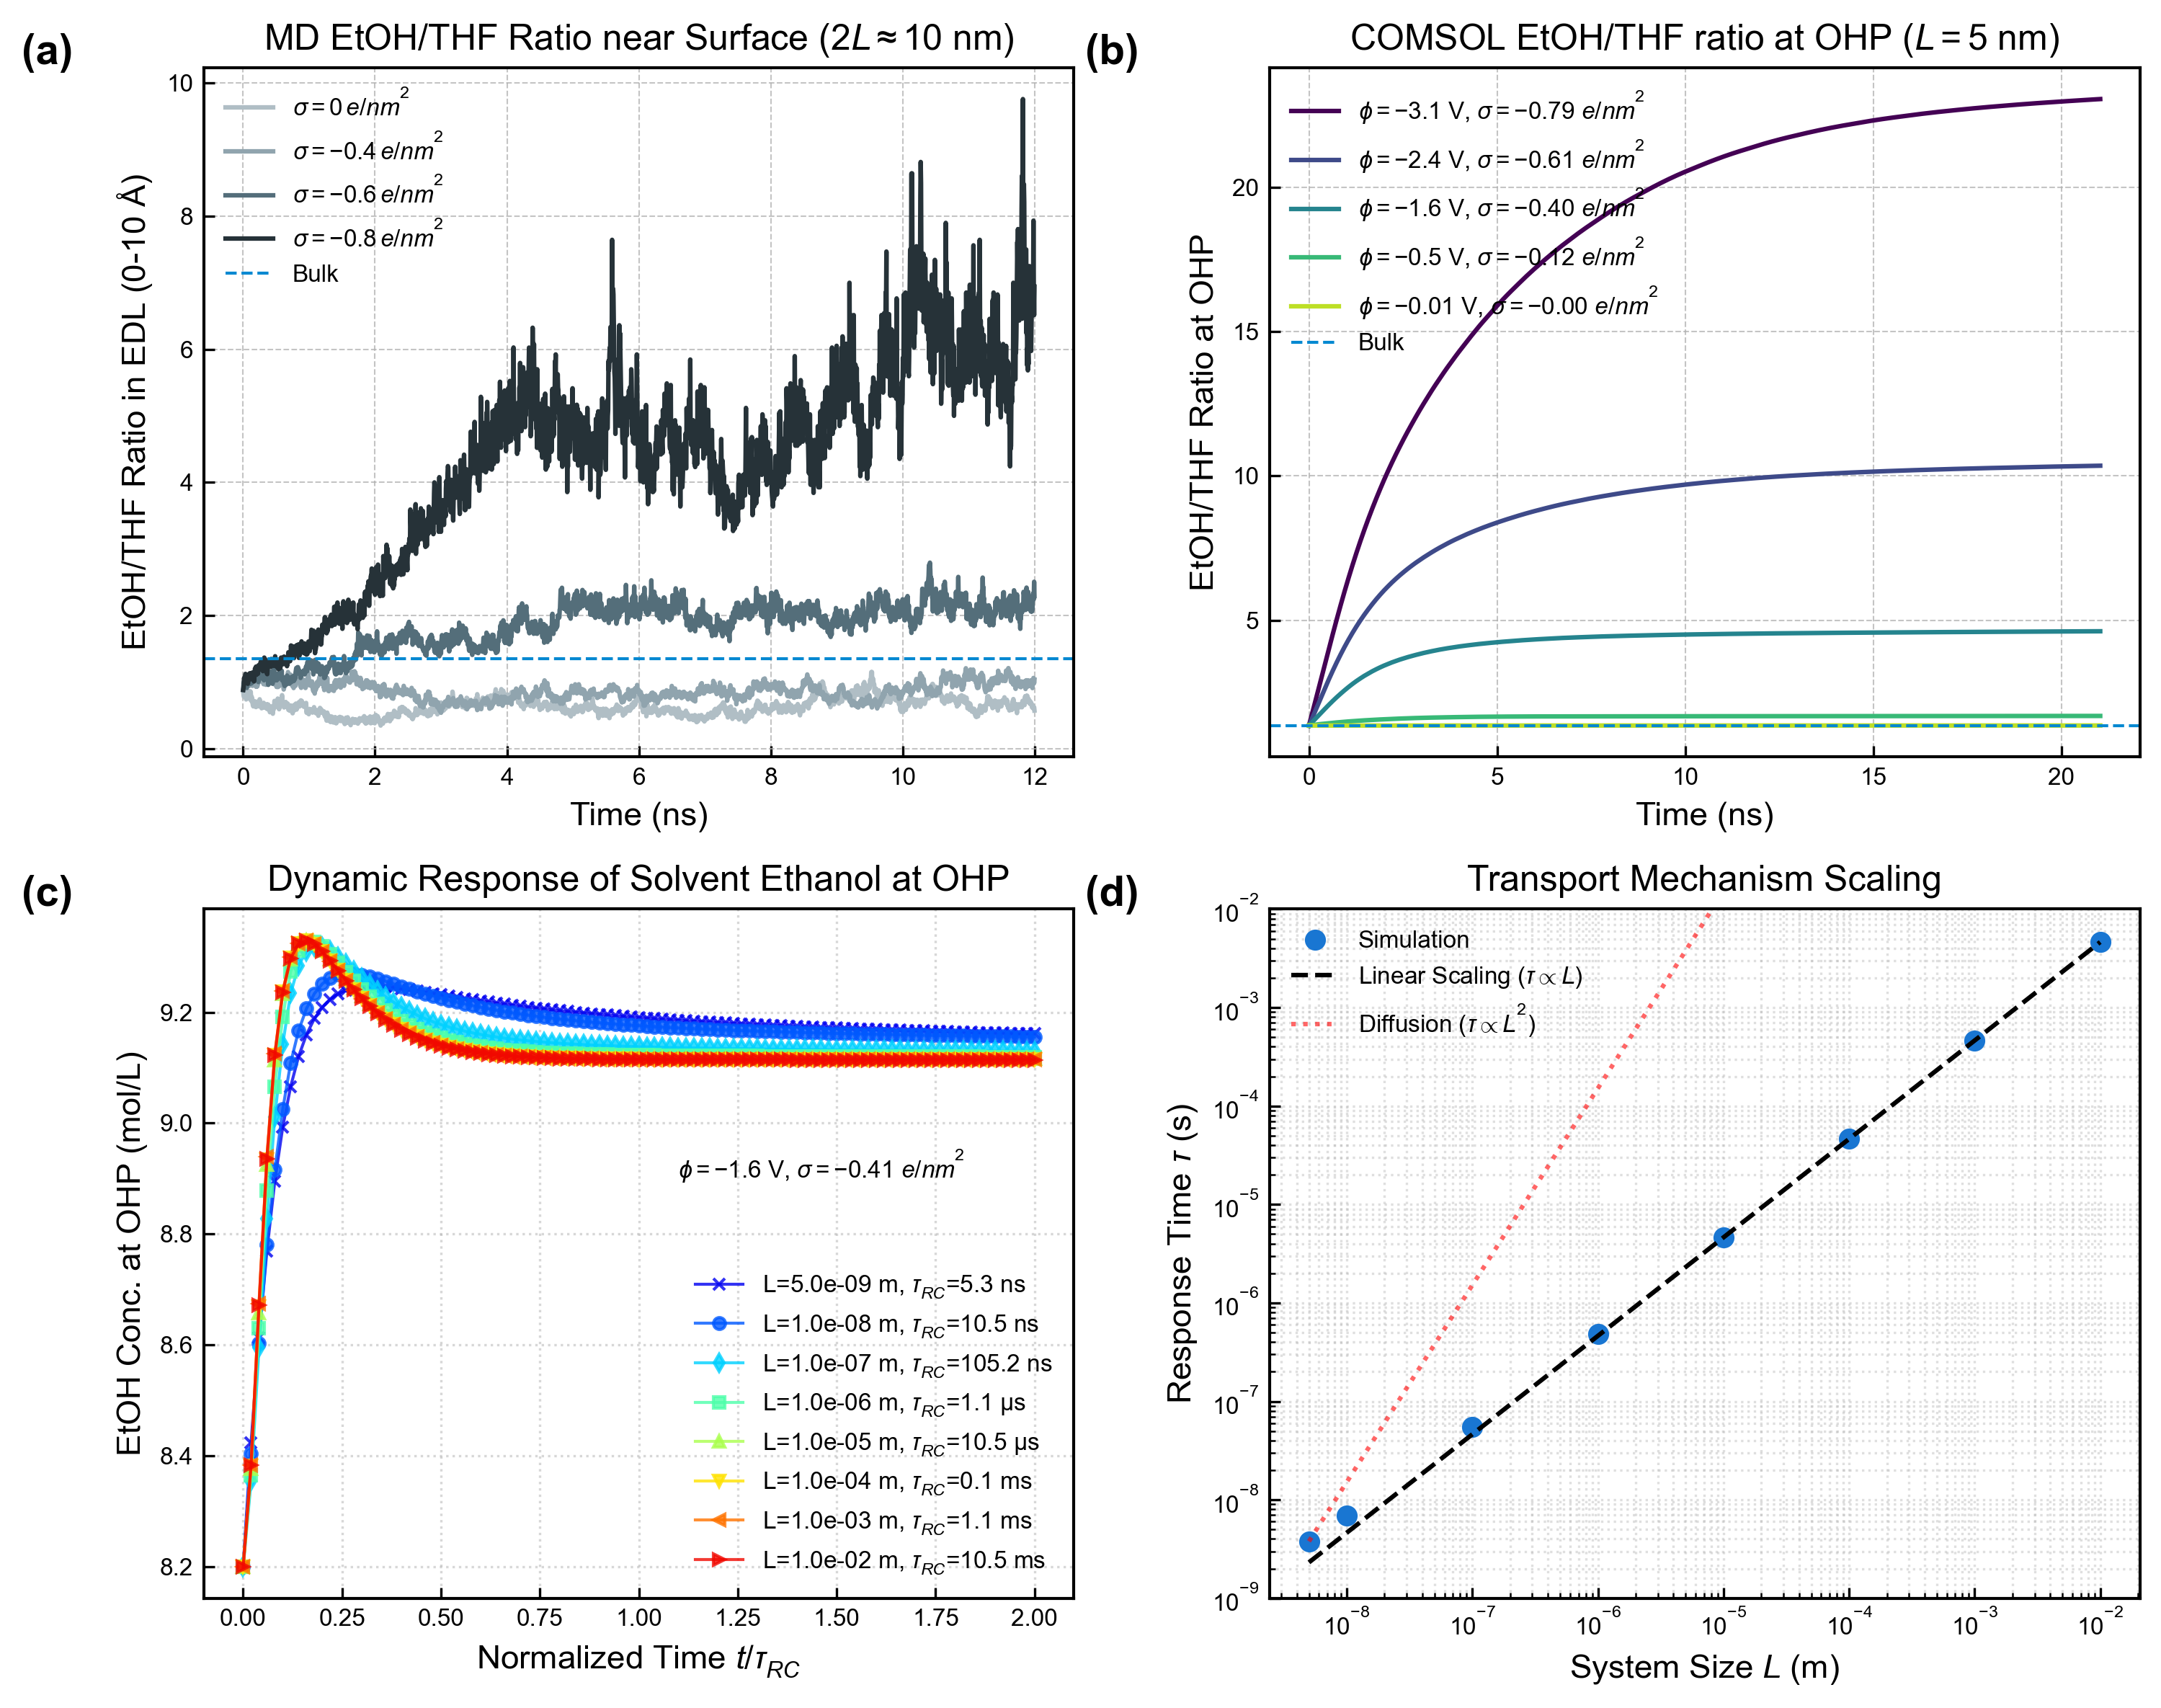

In [37]:

# ==========================================
# 3. PLOTTING
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
plt.subplots_adjust(wspace=0.3, hspace=0.35)

# -------------------------------------------------------
# PANEL A: Microscopic Dynamics (MD)
# -------------------------------------------------------
ax = axes[0, 0]
if not df_md.empty:
    # Map column names to charge labels
    labels_md = {
        'DC_0c': r'$\sigma= 0 \, e/nm^2$',
        'DC_0.4c': r'$\sigma= -0.4 \, e/nm^2$',
        'DC_0.6c': r'$\sigma= -0.6 \, e/nm^2$',
        'DC_0.8c': r'$\sigma= -0.8 \, e/nm^2$'
    }
    # Grey/Blue palette
    colors_md = ['#B0BEC5', '#90A4AE', '#546E7A', '#263238'] 
    
    cols_to_plot = ['DC_0c', 'DC_0.4c', 'DC_0.6c', 'DC_0.8c']
    for i, col in enumerate(cols_to_plot):
        if col in df_md.columns:
            ax.plot(df_md['time']/1000, df_md[col], label=labels_md.get(col, col), 
                    color=colors_md[i], linewidth=1.5)
            

ax.axhline(500/370, color='#0288D1', linestyle='--', linewidth=1, label='Bulk')
ax.grid(which='major', axis='both', linestyle='--', linewidth=0.5, zorder=0, alpha=0.75)
ax.set_xlabel('Time (ns)')
ax.set_ylabel(r'EtOH/THF Ratio in EDL (0-10 $\mathrm{\AA}$)')
ax.set_title(r'MD EtOH/THF Ratio near Surface ($2L \approx 10$ nm)')
ax.legend(frameon=False, loc='upper left')
ax.text(-0.15, 1.05, "(a)", transform=ax.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


# -------------------------------------------------------
# PANEL B: Macroscopic Dynamics (COMSOL L=5nm)
# -------------------------------------------------------
ax = axes[0, 1]
if not df_b.empty:
    unique_phi = sorted(df_b['phi_solid'].unique())
    # Viridis colormap for potentials
    colors_b = plt.cm.viridis(np.linspace(0, 0.9, len(unique_phi)))
    
    for i, phi in enumerate(unique_phi):
        df_p = df_b[df_b['phi_solid'] == phi]
        
        # Get final surface charge for the legend6
        # Convert from C/m^2 to e/nm^2
        final_rho = df_p['Surface_Charge'].iloc[-1] / 1.602e-19 * 1e-18
        
        # Create detailed label
        label_text = f"$\\phi={phi}$ V, $\\sigma={final_rho:.2f}$ $e/nm^2$"
        
        ax.plot(df_p['Time']*1e6, df_p['Ratio_OHP'], label=label_text, 
                color=colors_b[i], linewidth=1.5)

ax.axhline(8.2/6.1, color='#0288D1', linestyle='--', linewidth=1, label='Bulk')
ax.grid(which='major', axis='both', linestyle='--', linewidth=0.5, zorder=0, alpha=0.75)

ax.set_xlabel('Time (ns)')
ax.set_ylabel('EtOH/THF Ratio at OHP')
ax.set_title(r'COMSOL EtOH/THF ratio at OHP ($L=5$ nm)')
# Legend with 2 columns if too many entries
ax.legend(frameon=False, loc='upper left', ncol=1)
ax.text(-0.15, 1.05, "(b)", transform=ax.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


# -------------------------------------------------------
# PANEL C: Master Curve (All L_cell)
# -------------------------------------------------------
ax = axes[1, 0]
# Plot ALL L values found in file
markers = ['x', 'o', 'd', 's', '^', 'v', '<', '>']
colors_c = plt.cm.jet(np.linspace(0.1, 0.9, len(results_scaling)))

for i, res in enumerate(results_scaling):
    L_mm = res['L_mm']
    L_m = res['L_m']
    tau_RC_ms = res['tau_RC_ms']
    tau_ms = res['tau_ms']
    
    if tau_ms > 0:
        # Normalize time
        t_norm = res['time'] / tau_RC_ms
        conc = res['conc']
        
        # Format Label, include L and tau_RC; when L<1e-3 mm, use nm and ns; when L<0.1 mm, use um and us; when L>=0.1 mm, use mm and ms
        if L_mm < 1e-3:
            L_val = L_m  # m
            tau_val = tau_RC_ms * 1e6  # ns
            lbl = f"L={L_val:.1e} m, $\\tau_{{RC}}$={tau_val:.1f} ns"
        elif L_mm < 0.1:
            L_val = L_m  # m
            tau_val = tau_RC_ms * 1e3  # us
            lbl = f"L={L_val:.1e} m, $\\tau_{{RC}}$={tau_val:.1f} µs"
        else:
            L_val = L_m  # m
            tau_val = tau_RC_ms  # ms
            lbl = f"L={L_val:.1e} m, $\\tau_{{RC}}$={tau_val:.1f} ms"
            
        # Decimate points for clarity in plot
        # Keep ~50 points per curve
        # step = max(1, len(t_norm)//40)
        
        ax.plot(t_norm, conc, 
                marker=markers[i % len(markers)], markersize=4,
                linestyle='-', linewidth=1.0, 
                color=colors_c[i], label=lbl, alpha=0.8)

# indicate phi=-1.6V and rho_surf = -0.41 e/nm2 condition
ax.text(1.1, 8.9, r"$\phi=-1.6$ V, $\sigma=-0.41$ $e/nm^2$", fontsize=8, color='black')

ax.set_xlabel(r'Normalized Time $t/\tau_{RC}$')
ax.set_ylabel('EtOH Conc. at OHP (mol/L)')
ax.set_title('Dynamic Response of Solvent Ethanol at OHP')
# ax.set_xlim(0, 3.0) # Focus on the rise and settling
# Place legend outside or strictly inside? Inside is tight with 8 curves.
# Using small font
ax.legend(frameon=False, loc='lower right', ncol=1)
ax.grid(True, linestyle=':', alpha=0.5)
ax.text(-0.15, 1.05, "(c)", transform=ax.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


# -------------------------------------------------------
# PANEL D: Scaling Law
# -------------------------------------------------------
ax = axes[1, 1]

# Extract arrays for plotting
L_vals_m = []
tau_vals_s = []
for res in results_scaling:
    if res['tau_s'] > 1e-10: # Filter out zeros
        L_vals_m.append(res['L_m'])
        tau_vals_s.append(res['tau_s'])

L_vals_m = np.array(L_vals_m)
tau_vals_s = np.array(tau_vals_s)

if len(L_vals_m) > 0:
    # Plot Simulation Points
    ax.loglog(L_vals_m, tau_vals_s, 'o', color='#1976D2', markersize=6, label='Simulation')
    
    # --- Add Theoretical Slope 1 (RC) ---
    # Anchor to the largest L (Macroscopic)
    ref_idx = -1 
    k = tau_vals_s[ref_idx] / L_vals_m[ref_idx]
    
    # Create line covering the range
    L_line = np.logspace(np.log10(min(L_vals_m)), np.log10(max(L_vals_m)), 10)
    tau_line_rc = k * L_line
    ax.loglog(L_line, tau_line_rc, 'k--', label=r'Linear Scaling ($\tau \propto L$)')
    
    # --- Add Theoretical Slope 2 (Diffusion) for Comparison ---
    # Anchor to the smallest L (Microscopic/MD scale) to show divergence
    ref_idx_diff = 0
    c = tau_vals_s[ref_idx_diff] / (L_vals_m[ref_idx_diff]**2)
    tau_line_diff = c * (L_line**2)
    ax.loglog(L_line, tau_line_diff, 'r:', alpha=0.6, label=r'Diffusion ($\tau \propto L^2$)')

ax.set_ylim(1e-9, 1e-2)
ax.set_xlabel('System Size $L$ (m)')
ax.set_ylabel(r'Response Time $\tau$ (s)')
ax.set_title('Transport Mechanism Scaling')
ax.legend(frameon=False)
ax.grid(True, which='both', linestyle=':', alpha=0.4)
ax.text(-0.15, 1.05, "(d)", transform=ax.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

plt.tight_layout()
plt.savefig('Figure_5_Dynamics_Final.png', dpi=300, bbox_inches='tight')
plt.show()

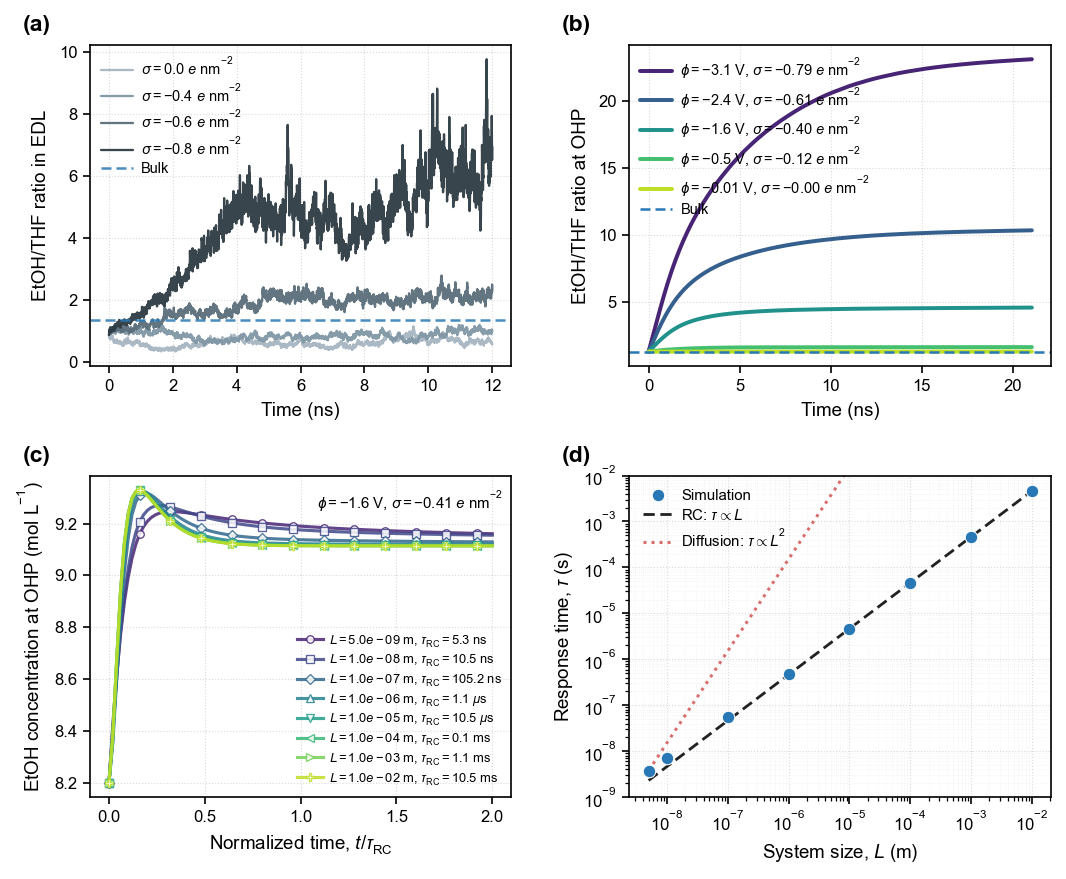

In [55]:
# ============================================================
# FIGURE 5: JACS-STYLE DYNAMICS AND SCALING
# Revised for consistency with Figures 3 and 4
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. PUBLICATION STYLE
# ------------------------------------------------------------
def set_pub_style():
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 8.5,
        "axes.labelsize": 9,
        "axes.titlesize": 9.5,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 7.2,

        # "axes.linewidth": 0.8,
        # "lines.linewidth": 1.8,

        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "xtick.minor.width": 0.6,
        "ytick.minor.width": 0.6,
        "xtick.major.size": 3.5,
        "ytick.major.size": 3.5,
        "xtick.minor.size": 2.0,
        "ytick.minor.size": 2.0,
        "xtick.direction": "out",
        "ytick.direction": "out",

        "figure.dpi": 150,
        "savefig.dpi": 600,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,

        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
    })


def style_axis(ax, grid=False, log_grid=False):
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        top=False,
        right=False,
        pad=2.5
    )

    if grid:
        ax.grid(
            True,
            which="major",
            linestyle=":",
            linewidth=0.55,
            color="#BDBDBD",
            alpha=0.55
        )
        ax.set_axisbelow(True)

    if log_grid:
        ax.grid(
            True,
            which="major",
            linestyle=":",
            linewidth=0.55,
            color="#BDBDBD",
            alpha=0.55
        )
        ax.grid(
            True,
            which="minor",
            linestyle=":",
            linewidth=0.35,
            color="#D5D5D5",
            alpha=0.40
        )
        ax.set_axisbelow(True)


def add_panel_label(ax, label, x=-0.16, y=1.03):
    ax.text(
        x, y, label,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        clip_on=False
    )


set_pub_style()


# ------------------------------------------------------------
# 2. FIGURE LAYOUT
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.8))

fig.subplots_adjust(
    left=0.095,
    right=0.985,
    bottom=0.105,
    top=0.97,
    wspace=0.28,
    hspace=0.34
)

legend_kw = dict(
    frameon=False,
    fontsize=7.0,
    handlelength=2.2,
    handletextpad=0.55,
    labelspacing=0.28,
    borderaxespad=0.35
)


# ============================================================
# PANEL A: MICROSCOPIC DYNAMICS (MD)
# ============================================================
ax = axes[0, 0]

if not df_md.empty:
    labels_md = {
        "DC_0c":   r"$\sigma = 0.0$ $e$ nm$^{-2}$",
        "DC_0.4c": r"$\sigma = -0.4$ $e$ nm$^{-2}$",
        "DC_0.6c": r"$\sigma = -0.6$ $e$ nm$^{-2}$",
        "DC_0.8c": r"$\sigma = -0.8$ $e$ nm$^{-2}$"
    }

    # stronger neutral palette for better visibility
    colors_md = ["#A7B6C2", "#8197A5", "#596E7A", "#2E3B43"]

    cols_to_plot = ["DC_0c", "DC_0.4c", "DC_0.6c", "DC_0.8c"]

    for i, col in enumerate(cols_to_plot):
        if col in df_md.columns:
            ax.plot(
                df_md["time"] / 1000,
                df_md[col],
                label=labels_md[col],
                color=colors_md[i],
                linewidth=1.1,
                alpha=0.95,
                solid_capstyle="round"
            )

ax.axhline(
    500 / 370,
    color="#2878B5",
    linestyle=(0, (4, 2)),
    linewidth=1.2,
    alpha=0.85,
    label="Bulk"
)

ax.set_xlabel("Time (ns)")
ax.set_ylabel("EtOH/THF ratio in EDL")

# optional title
# ax.set_title(r"MD response near the surface", pad=5)

ax.legend(loc="upper left", **legend_kw)
style_axis(ax, grid=True)
add_panel_label(ax, "(a)")


# ============================================================
# PANEL B: MACROSCOPIC DYNAMICS (COMSOL, L = 5 nm)
# ============================================================
ax = axes[0, 1]

if not df_b.empty:
    unique_phi = sorted(df_b["phi_solid"].unique())

    colors_b = plt.cm.viridis(np.linspace(0.10, 0.90, len(unique_phi)))

    for i, phi in enumerate(unique_phi):
        df_p = df_b[df_b["phi_solid"] == phi]

        final_rho = df_p["Surface_Charge"].iloc[-1] / 1.602e-19 * 1e-18

        label_text = (
            rf"$\phi = {phi:g}$ V, "
            rf"$\sigma = {final_rho:.2f}$ $e$ nm$^{{-2}}$"
        )

        ax.plot(
            df_p["Time"] * 1e6,
            df_p["Ratio_OHP"],
            label=label_text,
            color=colors_b[i],
            linewidth=1.9,
            solid_capstyle="round"
        )

ax.axhline(
    8.2 / 6.1,
    color="#2878B5",
    linestyle=(0, (4, 2)),
    linewidth=1.2,
    label="Bulk"
)

ax.set_xlabel("Time (ns)")
ax.set_ylabel("EtOH/THF ratio at OHP")

# optional title
# ax.set_title(r"Continuum response at the OHP", pad=5)

ax.legend(loc="upper left", **legend_kw)
style_axis(ax, grid=True)
add_panel_label(ax, "(b)")


# ============================================================
# PANEL C: MASTER CURVE
# ============================================================
ax = axes[1, 0]

markers = ["o", "s", "D", "^", "v", "<", ">", "P"]
colors_c = plt.cm.viridis(np.linspace(0.10, 0.90, len(results_scaling)))

for i, res in enumerate(results_scaling):
    L_mm = res["L_mm"]
    L_m = res["L_m"]
    tau_RC_ms = res["tau_RC_ms"]
    tau_ms = res["tau_ms"]

    if tau_ms > 0:
        t_norm = res["time"] / tau_RC_ms
        conc = res["conc"]

        if L_mm < 1e-3:
            L_val = L_m
            tau_val = tau_RC_ms * 1e6
            lbl = rf"$L={L_val:.1e}$ m, $\tau_{{\mathrm{{RC}}}}={tau_val:.1f}$ ns"
        elif L_mm < 0.1:
            L_val = L_m
            tau_val = tau_RC_ms * 1e3
            lbl = rf"$L={L_val:.1e}$ m, $\tau_{{\mathrm{{RC}}}}={tau_val:.1f}$ $\mu$s"
        else:
            L_val = L_m
            tau_val = tau_RC_ms
            lbl = rf"$L={L_val:.1e}$ m, $\tau_{{\mathrm{{RC}}}}={tau_val:.1f}$ ms"

        marker_interval = max(1, len(t_norm) // 12)

        ax.plot(
            t_norm,
            conc,
            marker=markers[i % len(markers)],
            markevery=marker_interval,
            markersize=3.6,
            markerfacecolor="white",
            markeredgewidth=0.65,
            linestyle="-",
            linewidth=1.5,
            color=colors_c[i],
            label=lbl,
            alpha=0.85
        )

ax.text(
    0.98, 0.96,
    r"$\phi=-1.6$ V, $\sigma=-0.41$ $e$ nm$^{-2}$",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=7.2
)

ax.set_xlabel(r"Normalized time, $t/\tau_{\mathrm{RC}}$")
ax.set_ylabel(r"EtOH concentration at OHP (mol L$^{-1}$)")

# optional title
# ax.set_title("Normalized solvent response", pad=5)

ax.legend(
    frameon=False,
    loc="lower right",
    fontsize=6.2,
    handlelength=2.0,
    handletextpad=0.45,
    labelspacing=0.22,
    borderaxespad=0.35
)

style_axis(ax, grid=True)
add_panel_label(ax, "(c)")


# ============================================================
# PANEL D: SCALING LAW
# ============================================================
ax = axes[1, 1]

L_vals_m = []
tau_vals_s = []

for res in results_scaling:
    if res["tau_s"] > 1e-10:
        L_vals_m.append(res["L_m"])
        tau_vals_s.append(res["tau_s"])

L_vals_m = np.asarray(L_vals_m)
tau_vals_s = np.asarray(tau_vals_s)

if len(L_vals_m) > 0:
    ax.loglog(
        L_vals_m,
        tau_vals_s,
        linestyle="none",
        marker="o",
        markersize=6,
        markerfacecolor="#2878B5",
        markeredgecolor="white",
        markeredgewidth=0.5,
        color="#2878B5",
        label="Simulation",
        zorder=3
    )

    ref_idx = -1
    k = tau_vals_s[ref_idx] / L_vals_m[ref_idx]

    L_line = np.logspace(
        np.log10(min(L_vals_m)),
        np.log10(max(L_vals_m)),
        100
    )
    tau_line_rc = k * L_line
    ax.loglog(
        L_line,
        tau_line_rc,
        color="#222222",
        linestyle=(0, (4, 2)),
        linewidth=1.35,
        label=r"RC: $\tau \propto L$"
    )

    ref_idx_diff = 0
    c = tau_vals_s[ref_idx_diff] / (L_vals_m[ref_idx_diff] ** 2)
    tau_line_diff = c * (L_line ** 2)
    ax.loglog(
        L_line,
        tau_line_diff,
        color="#D55E5E",
        linestyle=":",
        linewidth=1.45,
        alpha=0.9,
        label=r"Diffusion: $\tau \propto L^2$"
    )

ax.set_ylim(1e-9, 1e-2)
ax.set_xlabel(r"System size, $L$ (m)")
ax.set_ylabel(r"Response time, $\tau$ (s)")

# optional title
# ax.set_title("Response-time scaling", pad=5)

ax.legend(
    frameon=False,
    loc="upper left",
    handlelength=2.0,
    handletextpad=0.55,
    labelspacing=0.30
)

style_axis(ax, log_grid=True)
add_panel_label(ax, "(d)")


# ------------------------------------------------------------
# 3. DISPLAY / EXPORT
# ------------------------------------------------------------
plt.show()

fig.savefig("Figure_5_Dynamics_v2.png", bbox_inches="tight", dpi=500)
# fig.savefig("Figure_5_Dynamics_JACS.tif", dpi=600, bbox_inches="tight",
#             pad_inches=0.02, pil_kwargs={"compression": "tiff_lzw"})

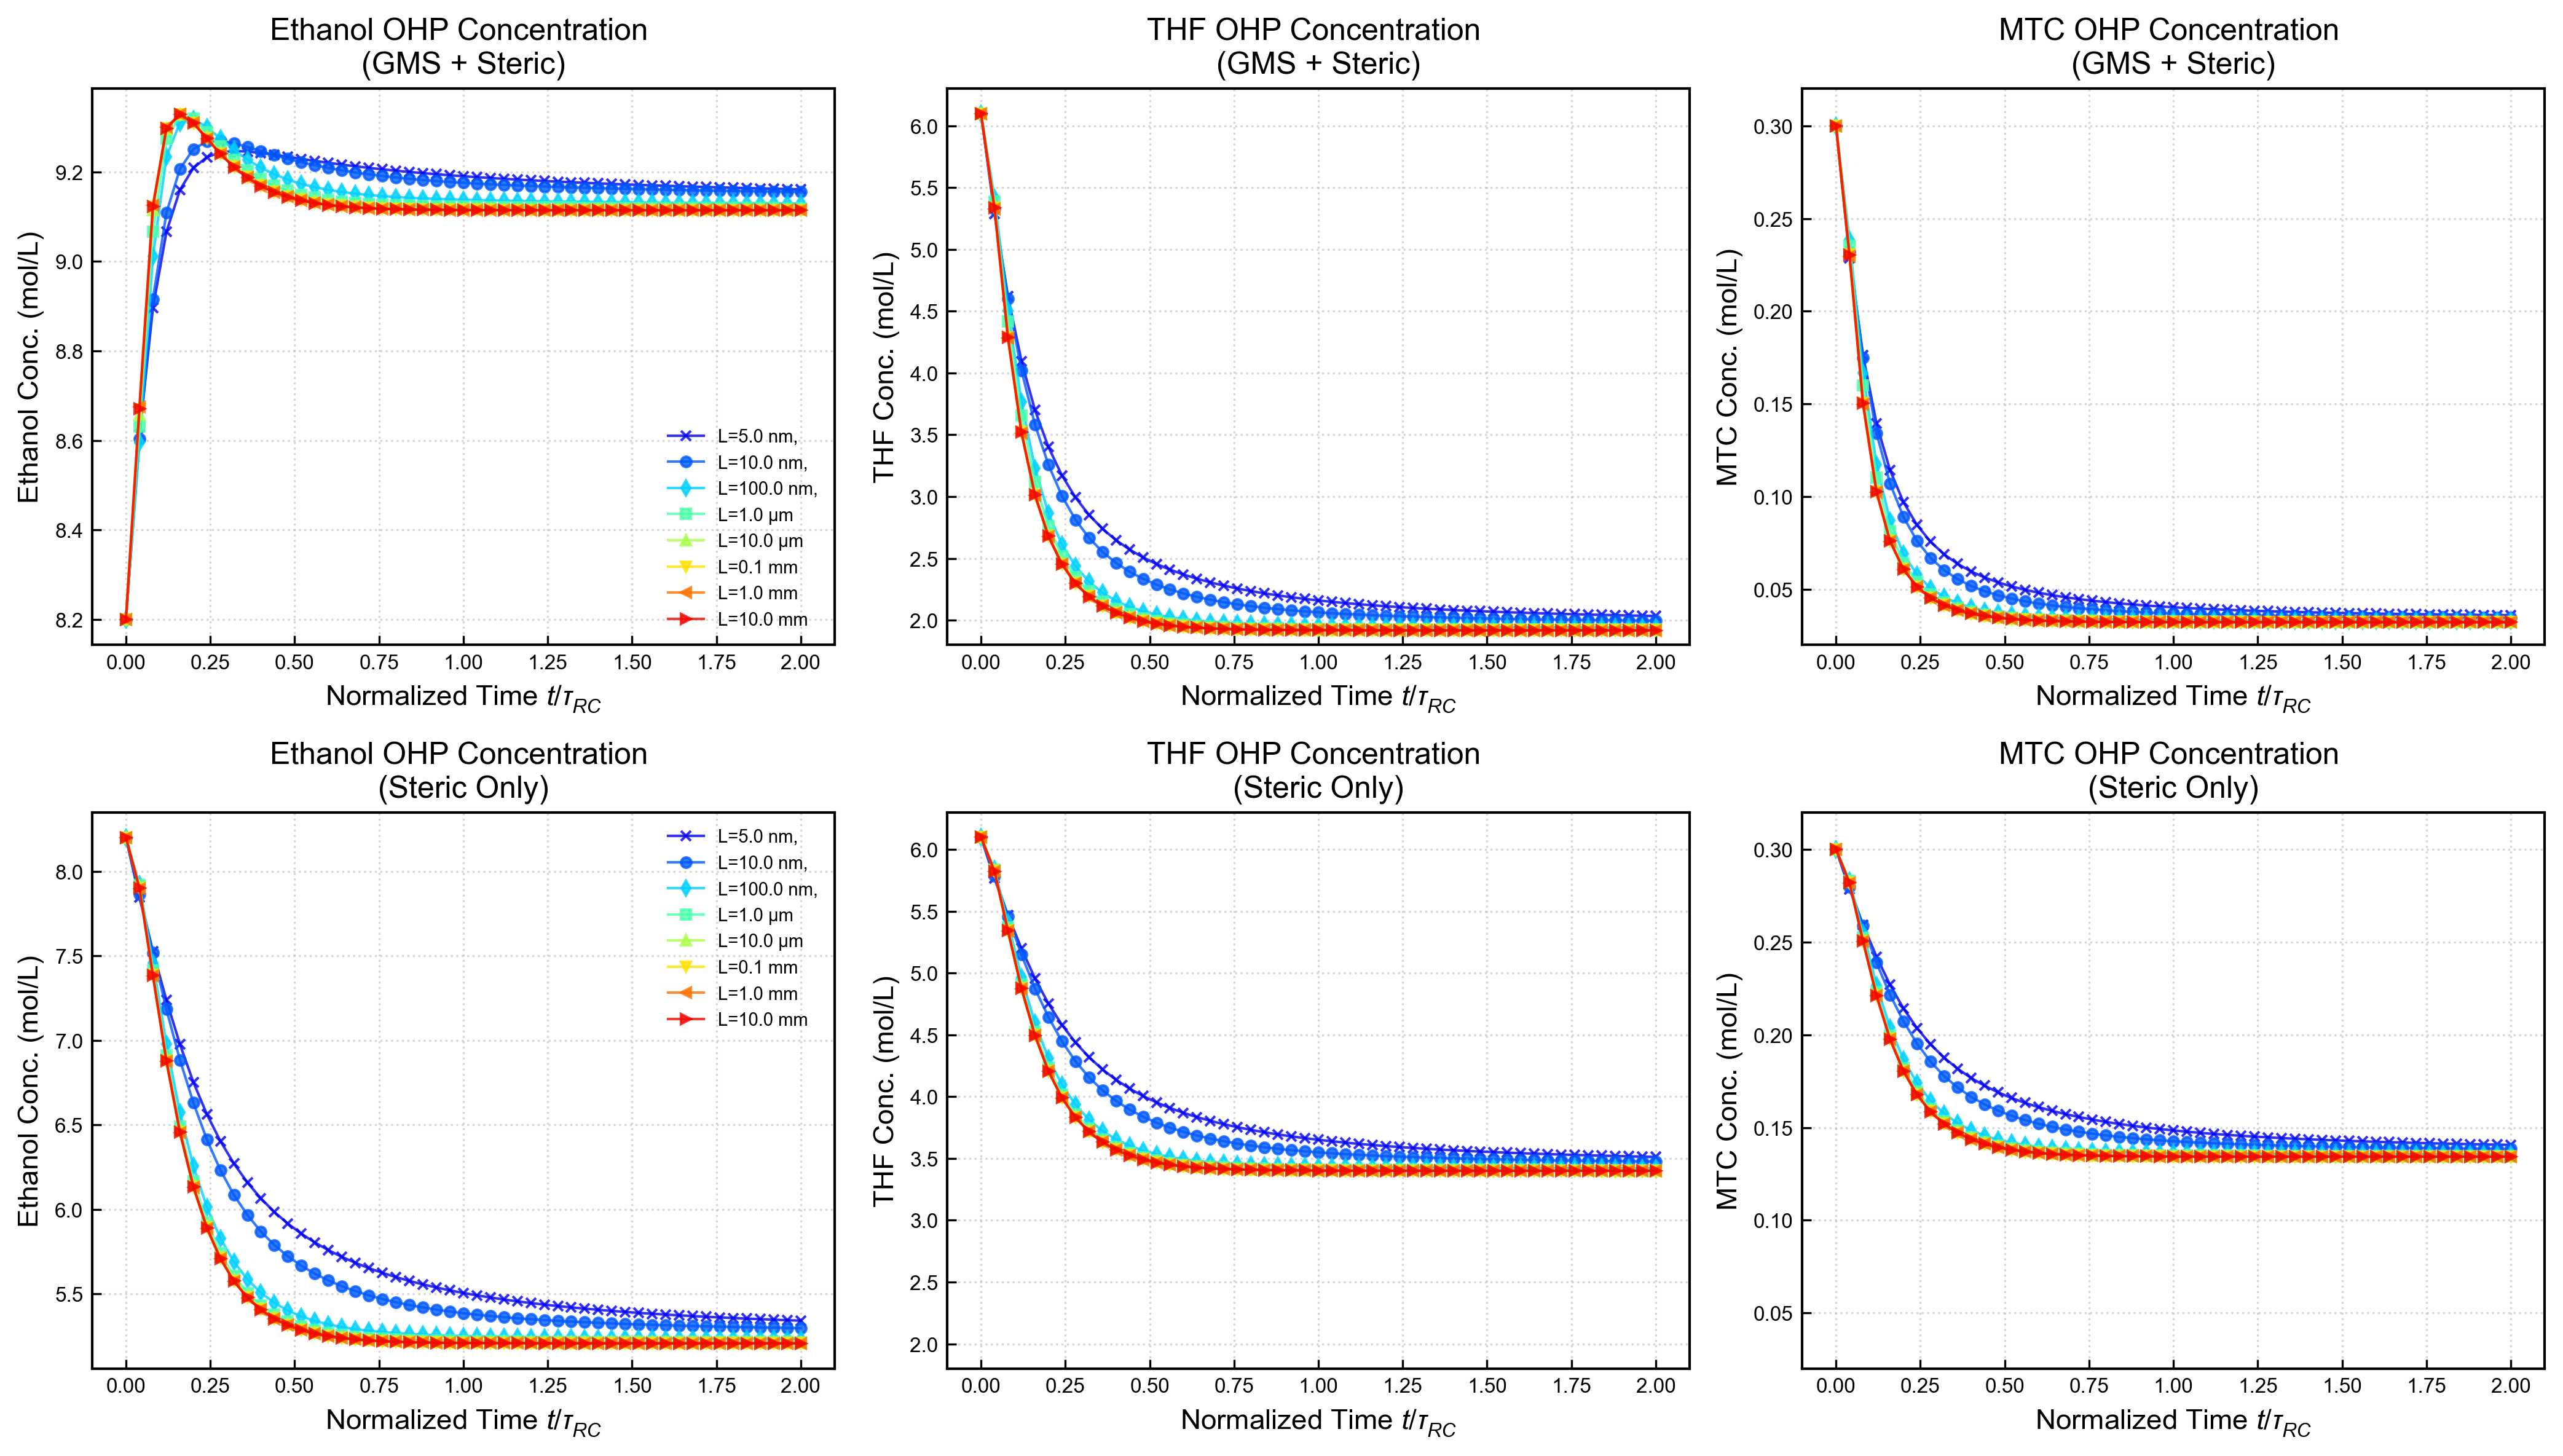

In [38]:
# ==========================================
# 1. PUBLICATION STYLE SETTINGS
# ==========================================
def set_pub_style():
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
        'font.size': 10,
        'axes.labelsize': 11,
        'axes.titlesize': 12,
        'legend.fontsize': 8,
        'axes.linewidth': 1.0,
        'lines.linewidth': 1.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'figure.dpi': 300
    })

set_pub_style()

# ==========================================
# 2. DATA PROCESSING FUNCTIONS
# ==========================================

# Constants for RC Time Calculation
DCat = 4.183E-10  # m^2/s (TMA+)
DAni = 4.075E-10  # m^2/s (BF4-)
lambda_D = 4.343E-10 # m (Debye length at 0.1M)
D_eff = (DCat + DAni) / 2

def calculate_tau_RC(L_mm):
    """Calculates theoretical RC time in ms given L in mm."""
    L_m = L_mm * 1e-3
    rc_time_s = (lambda_D * L_m) / D_eff
    return rc_time_s * 1e3 # Convert to ms

def load_and_clean_data(filename):
    """Loads COMSOL CSV and cleans column names."""
    try:
        df = pd.read_csv(filename, skiprows=4)
        clean_cols = []
        for c in df.columns:
            if "L_cell" in c: clean_cols.append("L_cell")
            elif "Time" in c: clean_cols.append("Time")
            elif "cEtOH" in c: clean_cols.append("cEtOH")
            elif "cTHF" in c: clean_cols.append("cTHF")
            elif "cMTC" in c: clean_cols.append("cMTC")
            else: clean_cols.append(c)
        df.columns = clean_cols
        return df
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
        return pd.DataFrame()

# Load Data
df_full = load_and_clean_data("COMSOL_OHP_concentration_phi1.6V.csv")
df_steric = load_and_clean_data("COMSOL_OHP_concentration_phi1.6V_steric_only.csv")

# ==========================================
# 3. PLOTTING THE 2x3 FIGURE
# ==========================================

# Setup Figure
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
plt.subplots_adjust(wspace=0.35, hspace=0.4)

# Configuration for Columns (Species) and Rows (Physics Models)
species_config = [
    ('cEtOH', 'Ethanol', 'mol/L'),
    ('cTHF', 'THF', 'mol/L'),
    ('cMTC', 'MTC', 'mol/L')
]

datasets = [
    ('Full Physics', df_full),
    ('Steric Effect Only', df_steric)
]

# Style settings for lines
markers = ['x', 'o', 'd', 's', '^', 'v', '<', '>']
colors = plt.cm.jet(np.linspace(0.1, 0.9, 8)) 

# --- Main Plotting Loop ---
for row_idx, (model_name, df) in enumerate(datasets):
    if df.empty: continue
    
    unique_L = sorted(df['L_cell'].unique())
    
    for col_idx, (col_key, species_name, unit) in enumerate(species_config):
        ax = axes[row_idx, col_idx]
        
        # Plot curve for each System Size L
        for i, L in enumerate(unique_L):
            # Extract and sort data for this L
            df_L = df[df['L_cell'] == L].sort_values('Time')
            time_ms = df_L['Time'].values
            conc = df_L[col_key].values
            
            # Normalize Time Axis
            tau_RC_ms = calculate_tau_RC(L)
            
            if tau_RC_ms > 0:
                t_norm = time_ms / tau_RC_ms
                
                # Format Legend Label nicely based on scale
                if L < 1e-3:   # < 1 µm -> use nm
                    lbl = f"L={L*1e6:.1f} nm,"
                elif L < 0.1:  # < 100 µm -> use µm
                    lbl = f"L={L*1e3:.1f} µm"
                else:          # >= 0.1 mm -> use mm
                    lbl = f"L={L:.1f} mm"
                
                # Decimate points for clearer plots (speed up rendering)
                step = max(1, len(t_norm)//40)
                
                ax.plot(t_norm[::step], conc[::step], 
                        marker=markers[i % len(markers)], markersize=4,
                        linestyle='-', linewidth=1.0, 
                        color=colors[i % len(colors)], label=lbl, alpha=0.8)

        # Axis Labels and Titles
        ax.set_xlabel(r'Normalized Time $t/\tau_{RC}$')
        ax.set_ylabel(f'{species_name} Conc. ({unit})')
        
        # Row-specific titles
        if row_idx == 0:
            ax.set_title(f'{species_name} OHP Concentration \n(GMS + Steric)')
        else:
            ax.set_title(f'{species_name} OHP Concentration \n(Steric Only)')
            
        ax.grid(True, linestyle=':', alpha=0.5)
        
        # Legend only on the first column to avoid clutter
        if col_idx == 0:
            ax.legend(frameon=False, loc='best', ncol=1, fontsize=7)
            # ax.set_ylim(4.9, 9.5)  # Specific y-limits for EtOH plot

        if col_idx == 1:
            ax.set_ylim(1.8, 6.3)  # Specific y-limits for THF plot
        if col_idx == 2:
            ax.set_ylim(0.02, 0.32)    # Specific y-limits for MTC plot

plt.tight_layout()
plt.savefig('SI_Figure_Control_Cases.png', dpi=300, bbox_inches='tight')
plt.show()

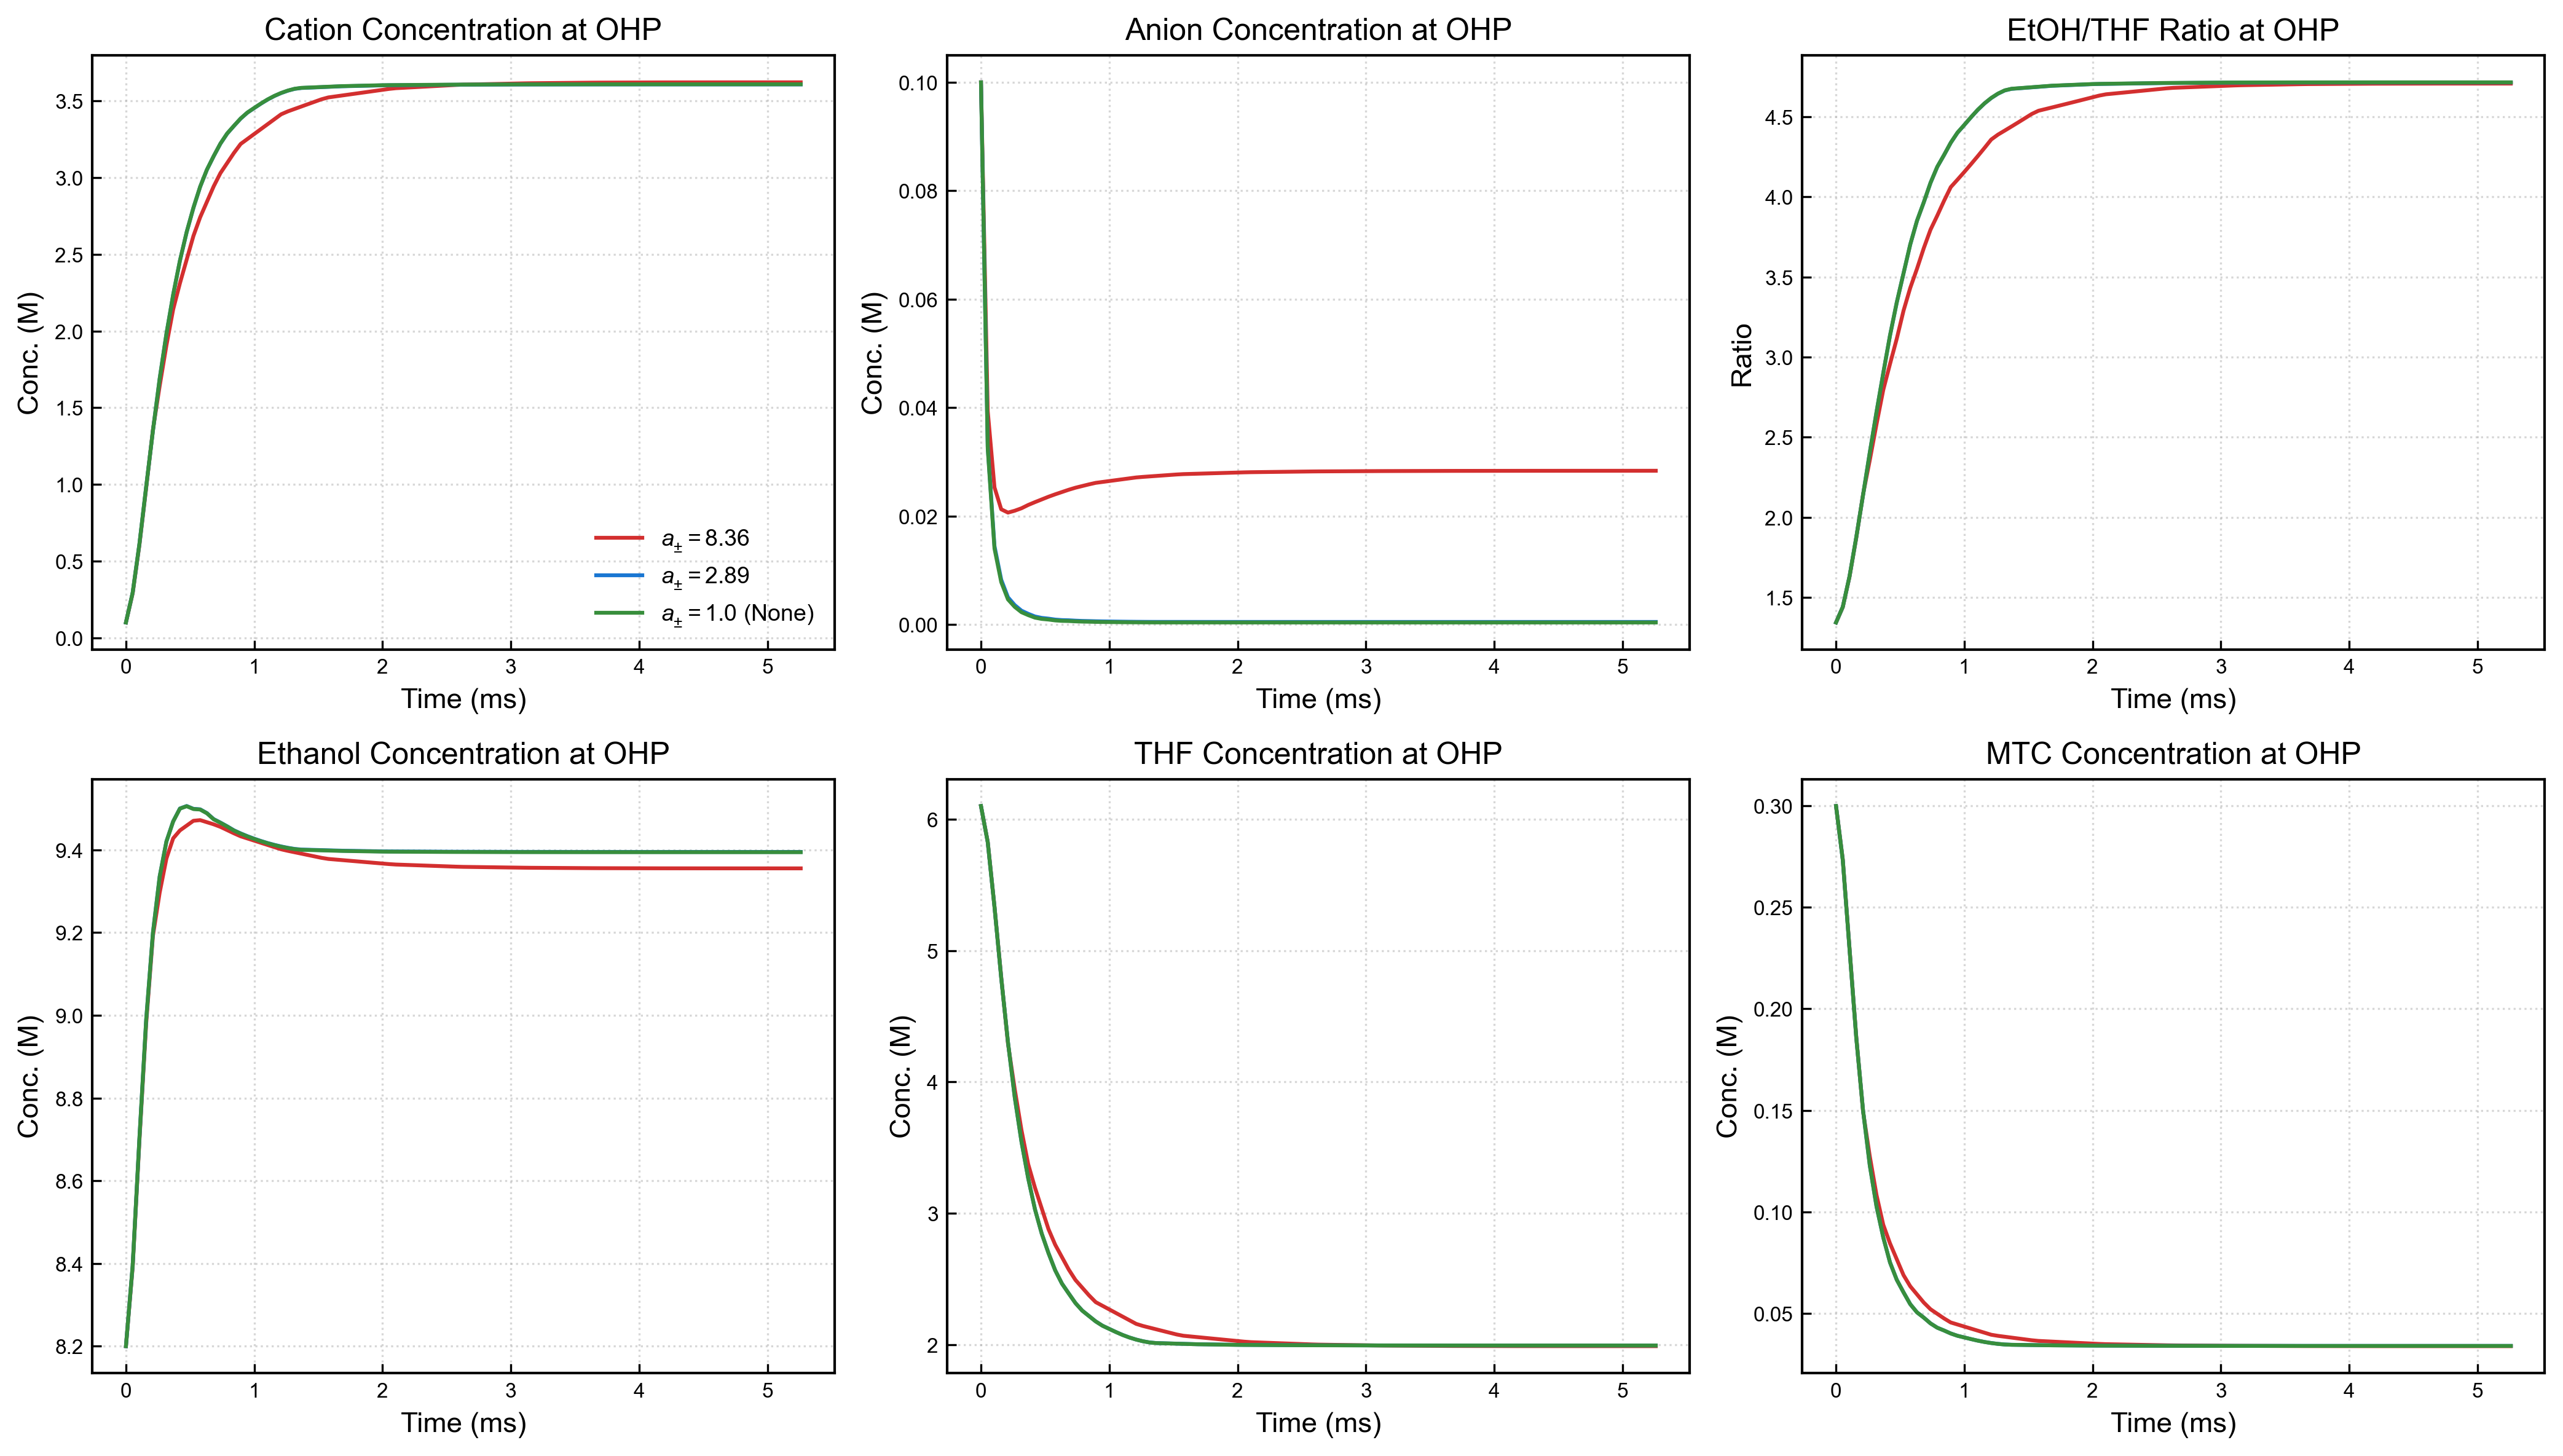

In [39]:
# ==========================================
# 1. PUBLICATION STYLE SETTINGS
# ==========================================
def set_pub_style():
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
        'font.size': 10,
        'axes.labelsize': 11,
        'axes.titlesize': 12,
        'legend.fontsize': 9,
        'axes.linewidth': 1.0,
        'lines.linewidth': 1.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'figure.dpi': 300
    })

set_pub_style()

# ==========================================
# 2. DATA LOADING & PROCESSING
# ==========================================
def load_and_clean_scaling_data(filename):
    """Loads COMSOL CSV for cation-anion scaling and cleans columns."""
    try:
        df = pd.read_csv(filename, skiprows=4)
        rename_map = {}
        for c in df.columns:
            if "a_12" in c: rename_map[c] = "a_12"
            elif "Time" in c: rename_map[c] = "Time"
            elif "EtOH/THF" in c: rename_map[c] = "Ratio"
            elif "cEtOH" in c: rename_map[c] = "cEtOH"
            elif "cTHF" in c: rename_map[c] = "cTHF"
            elif "cMTC" in c: rename_map[c] = "cMTC"
            elif "cCat" in c: rename_map[c] = "cCat"
            elif "cAni" in c: rename_map[c] = "cAni"
            elif "Surface" in c: rename_map[c] = "Sigma"
        
        df = df.rename(columns=rename_map)
        return df
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
        return pd.DataFrame()

df_scaling = load_and_clean_scaling_data("COMSOL_OHP_concentration_cation-anion-scaling.csv")

# ==========================================
# 3. PLOTTING THE 2x3 FIGURE
# ==========================================
if not df_scaling.empty:
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    plt.subplots_adjust(wspace=0.35, hspace=0.3)
    
    unique_a12 = sorted(df_scaling['a_12'].unique(), reverse=True) # Sort Descending
    colors = ['#D32F2F', '#1976D2', '#388E3C'] # Red, Blue, Green
    
    # Define Plot Configuration: (Attribute, Title, YLabel, Row, Col)
    plot_config = [
        ('cCat', 'Cation Concentration at OHP', 'Conc. (M)', 0, 0),
        ('cAni', 'Anion Concentration at OHP', 'Conc. (M)', 0, 1),
        ('Ratio', 'EtOH/THF Ratio at OHP', 'Ratio', 0, 2),
        ('cEtOH', 'Ethanol Concentration at OHP', 'Conc. (M)', 1, 0),
        ('cTHF', 'THF Concentration at OHP', 'Conc. (M)', 1, 1),
        ('cMTC', 'MTC Concentration at OHP', 'Conc. (M)', 1, 2)
    ]
    
    for (attr, title, ylabel, r, c) in plot_config:
        ax = axes[r, c]
        
        for i, a_val in enumerate(unique_a12):
            subset = df_scaling[df_scaling['a_12'] == a_val].sort_values('Time')
            
            # Label Formatting
            if abs(a_val - 1.0) < 0.1:
                label = f"$a_{{\\pm}} = 1.0$ (None)"
            else:
                label = f"$a_{{\\pm}} = {a_val:.2f}$"
            
            ax.plot(subset['Time'], subset[attr], label=label, color=colors[i], linewidth=1.5)
            
        ax.set_title(title)
        ax.set_xlabel("Time (ms)")
        ax.set_ylabel(ylabel)
        ax.grid(True, linestyle=':', alpha=0.5)
        
        # Legend (only on first subplot to save space)
        if r == 0 and c == 0:
            ax.legend(frameon=False, fontsize=9, loc='best')

    plt.tight_layout()
    plt.savefig('SI_Figure_Cation_Anion_Scaling.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("No data available to plot.")